# Projet IA — Prédiction de l'Attrition des Employés

## Livrable Final Consolidé

**Objectif** : Prédire si un employé va quitter l'entreprise (Attrition = Yes/No) à partir de données RH.

Ce notebook regroupe l'ensemble du pipeline de Machine Learning, de la préparation des données jusqu'à l'optimisation du modèle final.

---

## Sommaire

| N° | Section | Description |
|----|---------|-------------|
| **1** | [Installation des dépendances](#1) | Packages nécessaires (optionnel) |
| **2** | [Imports & Configuration](#2) | Bibliothèques et paramètres globaux |
| **3** | [Chargement des données brutes](#3) | Import et fusion des 5 fichiers CSV (general, surveys, time) |
| **4** | [Data Wrangling](#4) | Nettoyage, imputation, analyses univariée/bivariée/boxplots, encodage |
| **5** | [Analyse Exploratoire (EDA)](#5) | Distribution cible, corrélations |
| **6** | [Préparation pour le ML](#6) | Split train/test, stratification |
| **7** | [Modèles de Classification](#7) | Théorie des 7 algorithmes + métriques d'évaluation |
| **8** | [Comparaison des Modèles](#8) | Métriques et visualisations |
| **9** | [Optimisation Bayésienne](#9) | Tuning du meilleur modèle |
| **10** | [Analyse Éthique](#10) | Impact des variables démographiques |
| **11** | [Dashboard & Insights](#11) | Synthèse visuelle des résultats |
---

<a id="1"></a>
## 1. Installation des Dépendances (Optionnel)

Si vous exécutez ce notebook pour la première fois, décommentez et exécutez la cellule ci-dessous pour installer les packages nécessaires.

In [217]:
# ══════════════════════════════════════════════════════════════════════════════
# INSTALLATION DES DÉPENDANCES (décommenter si nécessaire)
# ══════════════════════════════════════════════════════════════════════════════

# !pip install pandas numpy matplotlib seaborn scikit-learn missingno scikit-optimize

<a id="2"></a>
## 2. Imports & Configuration Globale

### Pourquoi ces bibliothèques ?

| Bibliothèque | Usage |
|--------------|-------|
| **pandas** | Manipulation de données tabulaires (DataFrames) |
| **numpy** | Calculs numériques et tableaux multidimensionnels |
| **matplotlib / seaborn** | Visualisations statistiques |
| **scikit-learn** | Algorithmes de ML, métriques, préprocessing |
| **missingno** | Visualisation des valeurs manquantes |
| **scikit-optimize** | Optimisation bayésienne des hyperparamètres |

In [218]:
# ══════════════════════════════════════════════════════════════════════════════
# IMPORTS
# ══════════════════════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import missingno as msno
import pickle
import time
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn : preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

# Scikit-learn : modèles
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Scikit-learn : métriques
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report, make_scorer
)

# Optimisation bayésienne
try:
    from skopt import BayesSearchCV
    from skopt.space import Integer, Categorical, Real
    SKOPT_AVAILABLE = True
except ImportError:
    SKOPT_AVAILABLE = False
    print("scikit-optimize non installé. Section optimisation désactivée.")

# ══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION GLOBALE
# ══════════════════════════════════════════════════════════════════════════════

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style="whitegrid", palette="muted")

SEED = 42          # Reproductibilité
TEST_SIZE = 0.3    # 70% train / 30% test

COLORS = {
    'primary': '#2E86AB', 'danger': '#E84855', 'success': '#3BB273',
    'warning': '#F6AE2D', 'neutral': '#8D99AE', 'bg': '#F8F9FA'
}

print("    Imports et configuration OK")
print(f"   Random seed : {SEED}")
print(f"   Test size   : {TEST_SIZE*100:.0f}%")

    Imports et configuration OK
   Random seed : 42
   Test size   : 30%


<a id="3"></a>
## 3. Chargement des Données Brutes

### Description du jeu de données

Les données proviennent d'une entreprise fictive et contiennent des informations sur **4410 employés** :
- **general_data.csv** : Informations démographiques et professionnelles (âge, département, salaire, etc.)
- **employee_survey_data.csv** : Résultats d'enquêtes de satisfaction
- **manager_survey_data.csv** : Évaluations par les managers
- **in_time.csv / out_time.csv** : Heures d'arrivée et de départ (pour calculer le temps de travail)

La variable cible est **Attrition** : "Yes" si l'employé a quitté l'entreprise, "No" sinon.

In [219]:
# ══════════════════════════════════════════════════════════════════════════════
# CHARGEMENT DES FICHIERS CSV
# ══════════════════════════════════════════════════════════════════════════════

BASE = "Data_origin/"

general_data = pd.read_csv(BASE + "general_data.csv")
emp_survey   = pd.read_csv(BASE + "employee_survey_data.csv")
mgr_survey   = pd.read_csv(BASE + "manager_survey_data.csv")
in_time      = pd.read_csv(BASE + "in_time.csv")
out_time     = pd.read_csv(BASE + "out_time.csv")

print("Fichiers chargés :")
print(f"   general_data     : {general_data.shape}")
print(f"   employee_survey  : {emp_survey.shape}")
print(f"   manager_survey   : {mgr_survey.shape}")
print(f"   in_time          : {in_time.shape}")
print(f"   out_time         : {out_time.shape}")

# Aperçu des données générales
general_data.head()

Fichiers chargés :
   general_data     : (4410, 24)
   employee_survey  : (4410, 4)
   manager_survey   : (4410, 3)
   in_time          : (4410, 262)
   out_time         : (4410, 262)


,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeID,Gender,...,NumCompaniesWorked,Over18,PercentSalaryHike,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsSinceLastPromotion,YearsWithCurrManager
0,51,No,Travel_Rarely,Sales,6,2,Life Sciences,1,1,Female,...,1.0,Y,11,8,0,1.0,6,1,0,0
1,31,Yes,Travel_Frequently,Research & Development,10,1,Life Sciences,1,2,Female,...,0.0,Y,23,8,1,6.0,3,5,1,4
2,32,No,Travel_Frequently,Research & Development,17,4,Other,1,3,Male,...,1.0,Y,15,8,3,5.0,2,5,0,3
3,38,No,Non-Travel,Research & Development,2,5,Life Sciences,1,4,Male,...,3.0,Y,11,8,3,13.0,5,8,7,5
4,32,No,Travel_Rarely,Research & Development,10,1,Medical,1,5,Male,...,4.0,Y,12,8,2,9.0,2,6,0,4


### 3.1 Calcul du Temps de Travail Moyen

Les fichiers `in_time.csv` et `out_time.csv` contiennent les heures d'arrivée et de départ des employés pour chaque jour. On calcule le temps de travail moyen par employé, ce qui peut être un indicateur important de l'attrition.

In [220]:
# ══════════════════════════════════════════════════════════════════════════════
# CALCUL DU TEMPS DE TRAVAIL MOYEN
# ══════════════════════════════════════════════════════════════════════════════

# Conversion des colonnes de temps en datetime
date_cols = [c for c in in_time.columns if c != 'EmployeeID']
in_time[date_cols] = in_time[date_cols].apply(pd.to_datetime)
out_time[date_cols] = out_time[date_cols].apply(pd.to_datetime)

# Calcul de la durée de travail par jour
work_duration = out_time[date_cols] - in_time[date_cols]

# Temps de travail moyen par employé (en secondes)
avg_working_time = work_duration.mean(axis=1)
time_data = pd.DataFrame({
    'EmployeeID': in_time['EmployeeID'],
    'avg_working_time_seconds': avg_working_time.dt.total_seconds()
})

print(f"Temps de travail moyen calculé pour {len(time_data)} employés")
print(f"Statistiques du temps de travail moyen (en heures) :")
print(f"   Min    : {time_data['avg_working_time_seconds'].min()/3600:.2f}h")
print(f"   Max    : {time_data['avg_working_time_seconds'].max()/3600:.2f}h")
print(f"   Moyenne: {time_data['avg_working_time_seconds'].mean()/3600:.2f}h")

Temps de travail moyen calculé pour 4410 employés
Statistiques du temps de travail moyen (en heures) :
   Min    : 5.95h
   Max    : 11.03h
   Moyenne: 7.70h


In [221]:
# ══════════════════════════════════════════════════════════════════════════════
# FUSION DE TOUS LES DATASETS
# ══════════════════════════════════════════════════════════════════════════════

# Fusion des données RH
df = (general_data
      .merge(emp_survey, on="EmployeeID", how="left")
      .merge(mgr_survey, on="EmployeeID", how="left")
      .merge(time_data, on="EmployeeID", how="left"))

# Suppression des colonnes inutiles (constantes)
cols_to_drop = ['EmployeeCount', 'StandardHours', 'Over18']
cols_to_drop = [c for c in cols_to_drop if c in df.columns]
df = df.drop(columns=cols_to_drop)

print(f"Dataset fusionné : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print(f"Distribution de la cible (Attrition) :")
print(df['Attrition'].value_counts())
print(f"\n   Taux d'attrition : {(df['Attrition']=='Yes').mean()*100:.1f}%")

Dataset fusionné : 4410 lignes × 27 colonnes
Distribution de la cible (Attrition) :
Attrition
No     3699
Yes     711
Name: count, dtype: int64

   Taux d'attrition : 16.1%


In [222]:
# Vérification de la présence de avg_working_time_seconds
if 'avg_working_time_seconds' in df.columns:
    print("Variable 'avg_working_time_seconds' présente dans le dataset")
    print(f"   Valeurs non-nulles : {df['avg_working_time_seconds'].notna().sum()}")
else:
    print("ATTENTION : 'avg_working_time_seconds' ABSENTE !")
    print("   Exécutez d'abord la cellule de calcul du temps de travail (Section 3.1)")

print(f"Colonnes du dataset fusionné ({df.shape[1]}) :")
print(df.columns.tolist())

Variable 'avg_working_time_seconds' présente dans le dataset
   Valeurs non-nulles : 4410
Colonnes du dataset fusionné (27) :
['Age', 'Attrition', 'BusinessTravel', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeID', 'Gender', 'JobLevel', 'JobRole', 'MaritalStatus', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'EnvironmentSatisfaction', 'JobSatisfaction', 'WorkLifeBalance', 'JobInvolvement', 'PerformanceRating', 'avg_working_time_seconds']


<a id="4"></a>
## 4. Data Wrangling (Nettoyage des Données)

### 4.1 Identification des types de variables

Il est crucial de distinguer :
- **Variables numériques** : peuvent être utilisées directement par les algorithmes
- **Variables catégorielles** : doivent être encodées (One-Hot Encoding ou Label Encoding)

In [223]:
# Identification des types de colonnes
numerical_cols   = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"Variables numériques ({len(numerical_cols)}) :")
print(f"   {numerical_cols}")
print(f"Variables catégorielles ({len(categorical_cols)}) :")
print(f"   {categorical_cols}")

Variables numériques (20) :
   ['Age', 'DistanceFromHome', 'Education', 'EmployeeID', 'JobLevel', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'EnvironmentSatisfaction', 'JobSatisfaction', 'WorkLifeBalance', 'JobInvolvement', 'PerformanceRating', 'avg_working_time_seconds']
Variables catégorielles (7) :
   ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus']


### 4.2 Gestion des Valeurs Manquantes

Les valeurs manquantes peuvent fausser l'entraînement des modèles. Plusieurs stratégies existent :
- **Suppression** : si peu de données sont manquantes
- **Imputation par la médiane** : pour les variables numériques (robuste aux outliers)
- **Imputation par le mode** : pour les variables catégorielles

Valeurs manquantes par colonne :
NumCompaniesWorked         19
TotalWorkingYears           9
EnvironmentSatisfaction    25
JobSatisfaction            20
WorkLifeBalance            38
dtype: int64


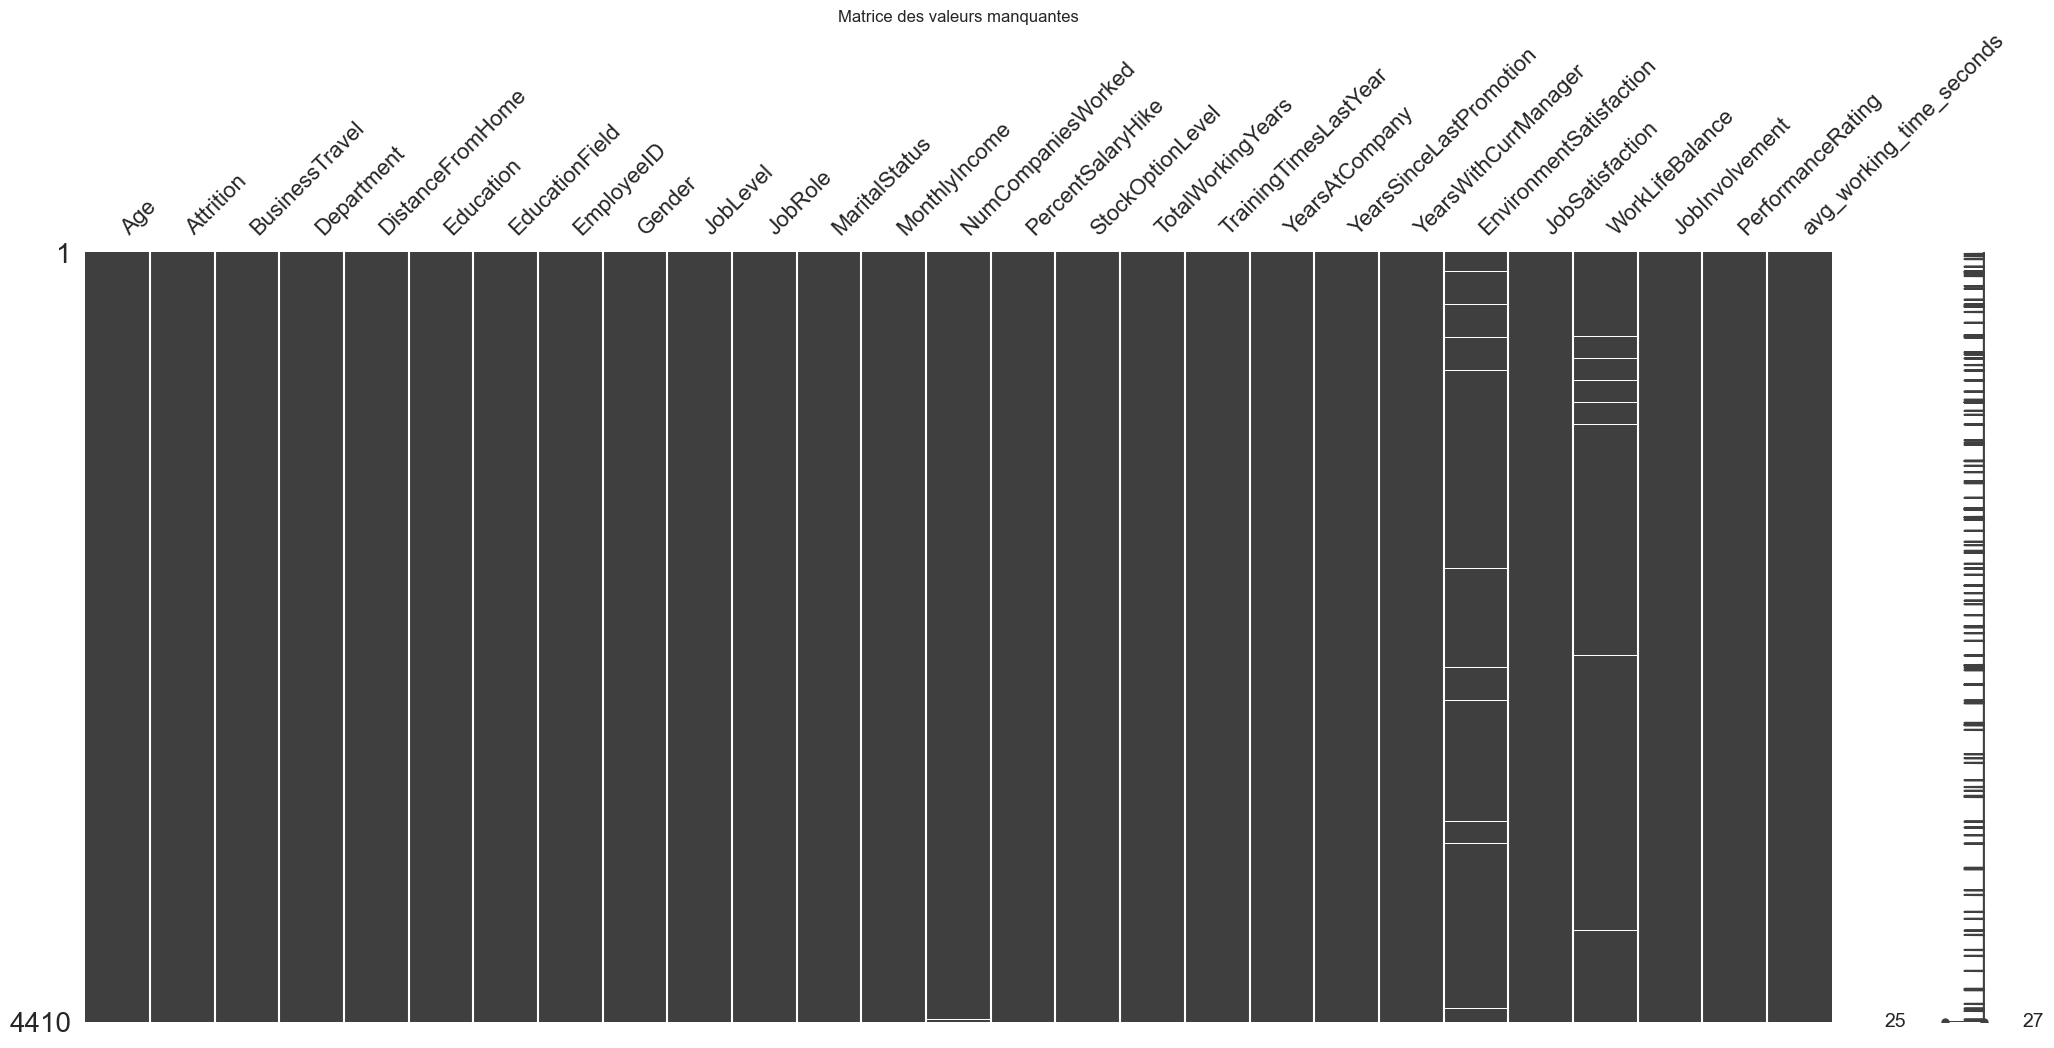

In [224]:
# Visualisation des valeurs manquantes
print("Valeurs manquantes par colonne :")
missing = df.isnull().sum()
print(missing[missing > 0])

# Visualisation graphique
msno.matrix(df)
plt.title("Matrice des valeurs manquantes")
plt.show()

In [225]:
# Imputation des valeurs manquantes
df_clean = df.copy()

# Numériques : imputation par la médiane
num_cols_with_na = df_clean.select_dtypes(include=[np.number]).columns
imputer_num = SimpleImputer(strategy="median")
df_clean[num_cols_with_na] = imputer_num.fit_transform(df_clean[num_cols_with_na])

# Catégorielles : imputation par le mode
for col in categorical_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col].fillna(df_clean[col].mode()[0], inplace=True)

print(f"Valeurs manquantes après imputation : {df_clean.isnull().sum().sum()}")

Valeurs manquantes après imputation : 0


### 4.3 Encodage des Variables Catégorielles

Les algorithmes de ML ne peuvent pas traiter directement les chaînes de caractères. 

**One-Hot Encoding** : crée une colonne binaire pour chaque modalité. 
- Exemple : `Department` → `Department_Sales`, `Department_HR`, `Department_R&D`

**Label Encoding** : convertit la variable cible en 0/1.
- `Attrition` : "No" → 0, "Yes" → 1

In [226]:
# Encodage de la variable cible
le = LabelEncoder()
df_clean['Attrition'] = le.fit_transform(df_clean['Attrition'])  # No=0, Yes=1

# One-Hot Encoding des variables catégorielles (sauf Attrition)
cat_cols_to_encode = [c for c in categorical_cols if c != 'Attrition']
df_encoded = pd.get_dummies(df_clean, columns=cat_cols_to_encode, drop_first=False)

print(f"Dataset après encodage : {df_encoded.shape[0]} lignes × {df_encoded.shape[1]} colonnes")
print(f"Nouvelles colonnes créées : {df_encoded.shape[1] - df_clean.shape[1]}")

Dataset après encodage : 4410 lignes × 47 colonnes
Nouvelles colonnes créées : 20


### 4.4 Analyse Univariée

L'analyse univariée permet d'étudier la distribution de chaque variable individuellement :
- **Variables numériques** : histogrammes pour visualiser la forme de la distribution (normale, asymétrique, bimodale)
- **Variables catégorielles** : diagrammes en barres pour voir la répartition des modalités

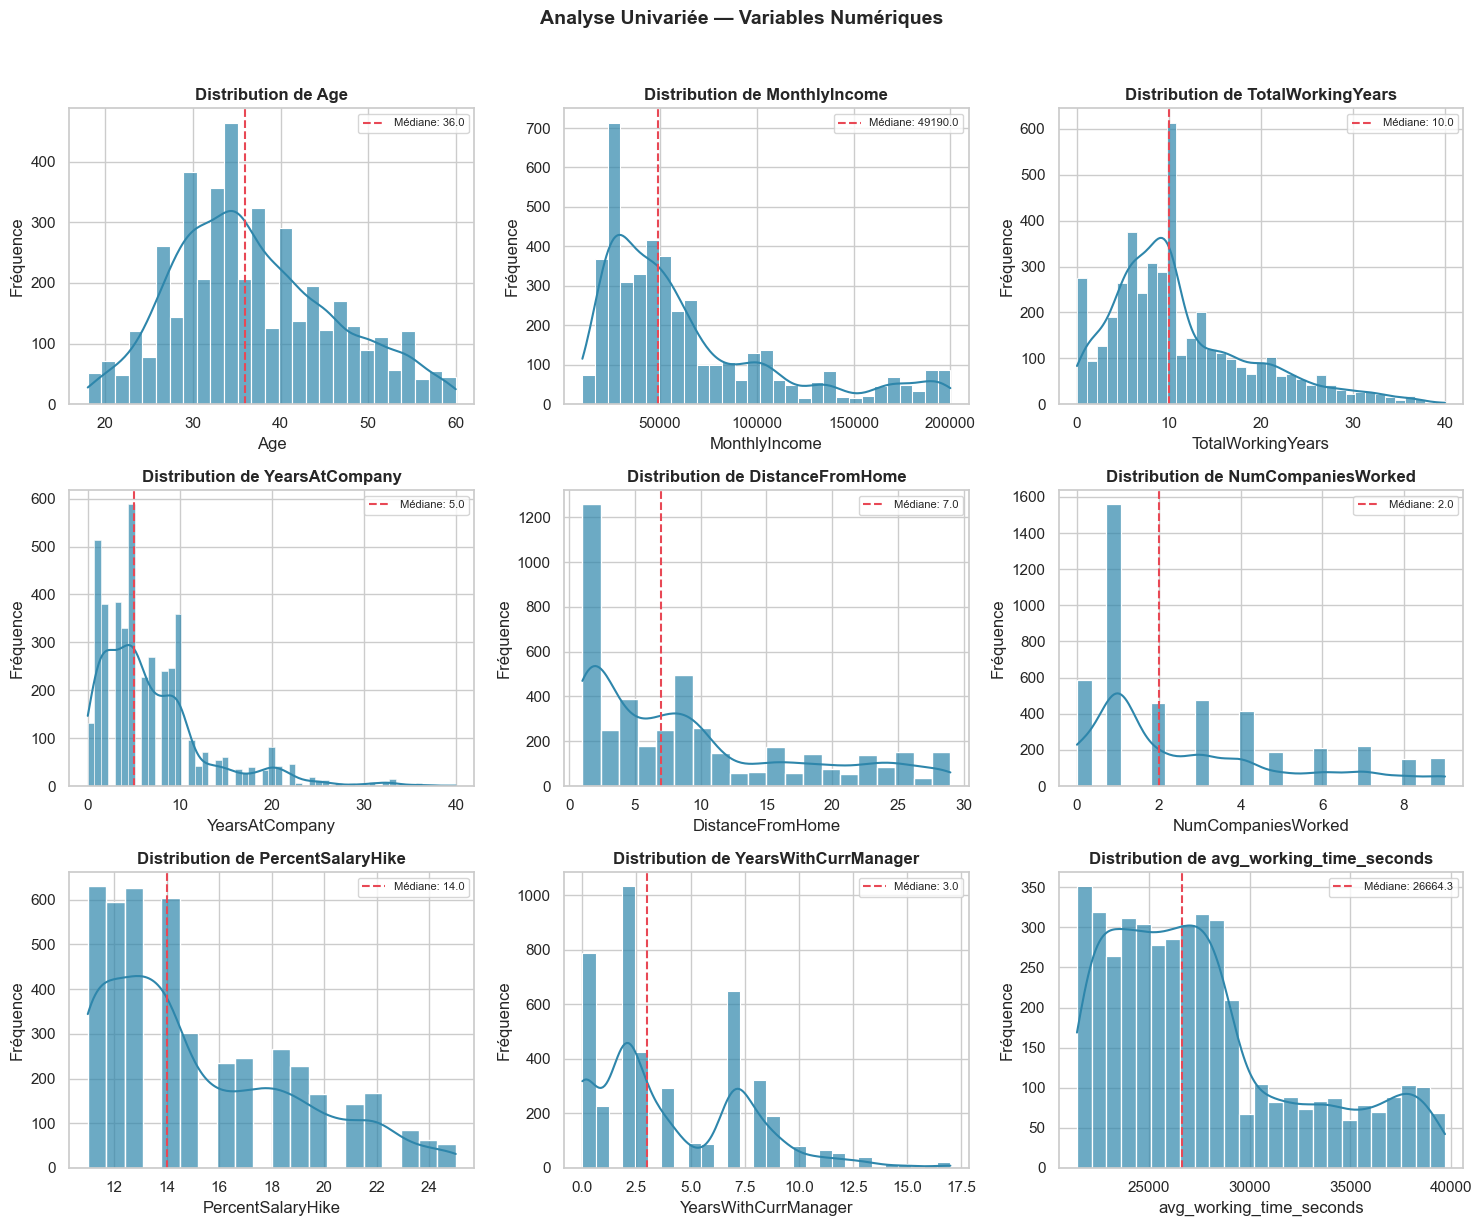

In [227]:
# ══════════════════════════════════════════════════════════════════════════════
# ANALYSE UNIVARIÉE — VARIABLES NUMÉRIQUES
# ══════════════════════════════════════════════════════════════════════════════

# Sélection des variables numériques clés pour l'analyse
key_numerical = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
                 'DistanceFromHome', 'NumCompaniesWorked', 'PercentSalaryHike',
                 'YearsWithCurrManager', 'avg_working_time_seconds']

# Filtrer les colonnes disponibles
key_numerical = [c for c in key_numerical if c in df_clean.columns]

# Création de la grille de graphiques
n_cols = 3
n_rows = (len(key_numerical) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for idx, col in enumerate(key_numerical):
    ax = axes[idx]
    sns.histplot(df_clean[col], kde=True, ax=ax, color=COLORS['primary'], alpha=0.7)
    ax.set_title(f"Distribution de {col}", fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel("Fréquence")
    
    # Ajouter la médiane
    median_val = df_clean[col].median()
    ax.axvline(median_val, color=COLORS['danger'], linestyle='--', label=f'Médiane: {median_val:.1f}')
    ax.legend(fontsize=8)

# Masquer les axes inutilisés
for idx in range(len(key_numerical), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Analyse Univariée — Variables Numériques", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

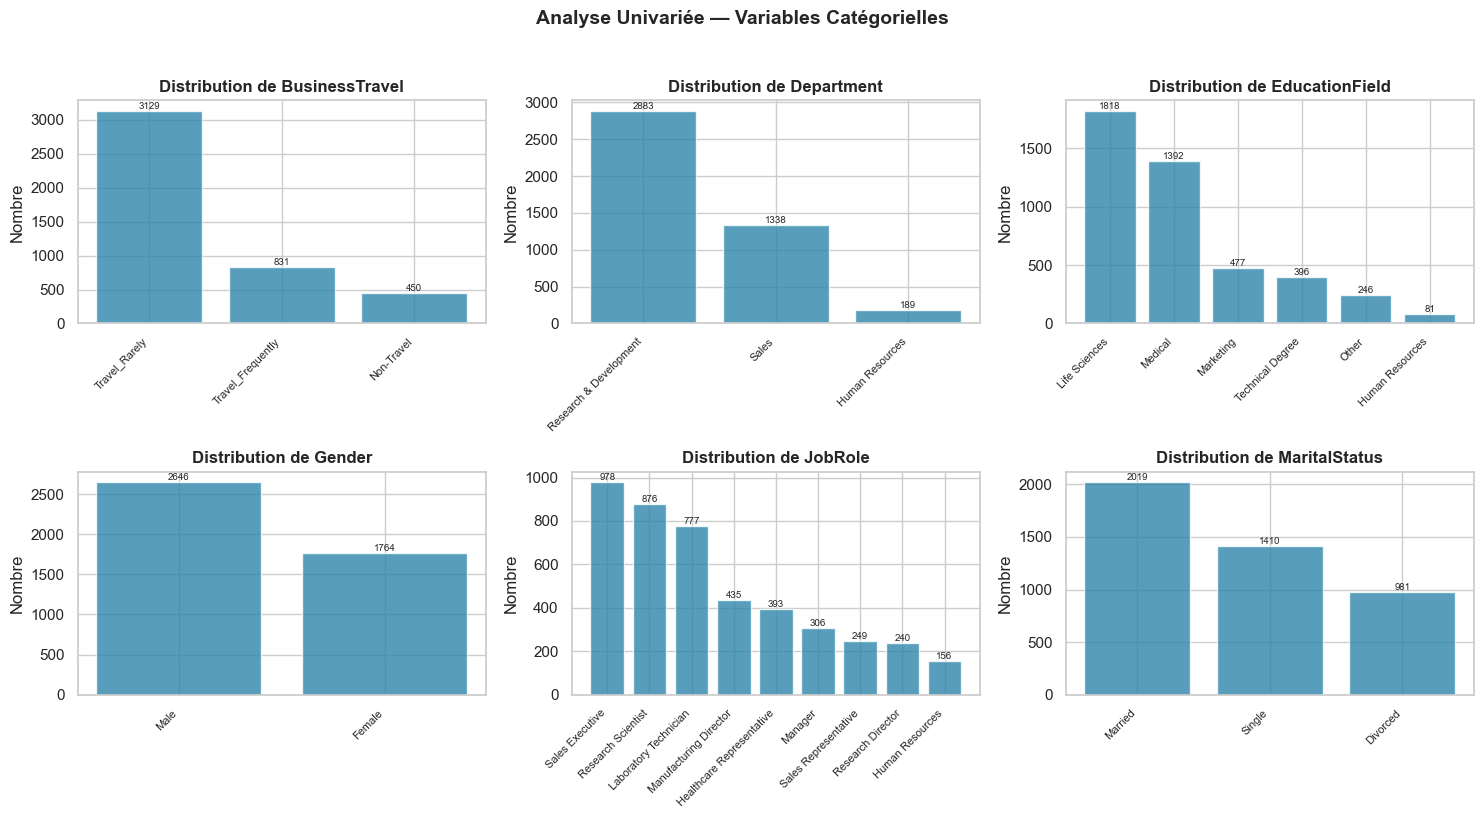

In [228]:
# ══════════════════════════════════════════════════════════════════════════════
# ANALYSE UNIVARIÉE — VARIABLES CATÉGORIELLES
# ══════════════════════════════════════════════════════════════════════════════

# Variables catégorielles à analyser (avant encodage)
key_categorical = [c for c in categorical_cols if c != 'Attrition']

# Création de la grille
n_cols = 3
n_rows = (len(key_categorical) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for idx, col in enumerate(key_categorical):
    ax = axes[idx]
    counts = df_clean[col].value_counts() if col != 'Attrition' else df[col].value_counts()
    bars = ax.bar(range(len(counts)), counts.values, color=COLORS['primary'], alpha=0.8)
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index, rotation=45, ha='right', fontsize=8)
    ax.set_title(f"Distribution de {col}", fontweight='bold')
    ax.set_ylabel("Nombre")
    
    # Ajouter les valeurs sur les barres
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height, f'{int(height)}',
                ha='center', va='bottom', fontsize=7)

# Masquer les axes inutilisés
for idx in range(len(key_categorical), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Analyse Univariée — Variables Catégorielles", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 4.5 Analyse Bivariée

L'analyse bivariée étudie les relations entre paires de variables numériques à l'aide d'un **pairplot**. Cela permet de :
- Détecter des corrélations linéaires ou non-linéaires
- Identifier des clusters naturels dans les données
- Repérer des outliers potentiels

Génération du pairplot (peut prendre quelques secondes)...


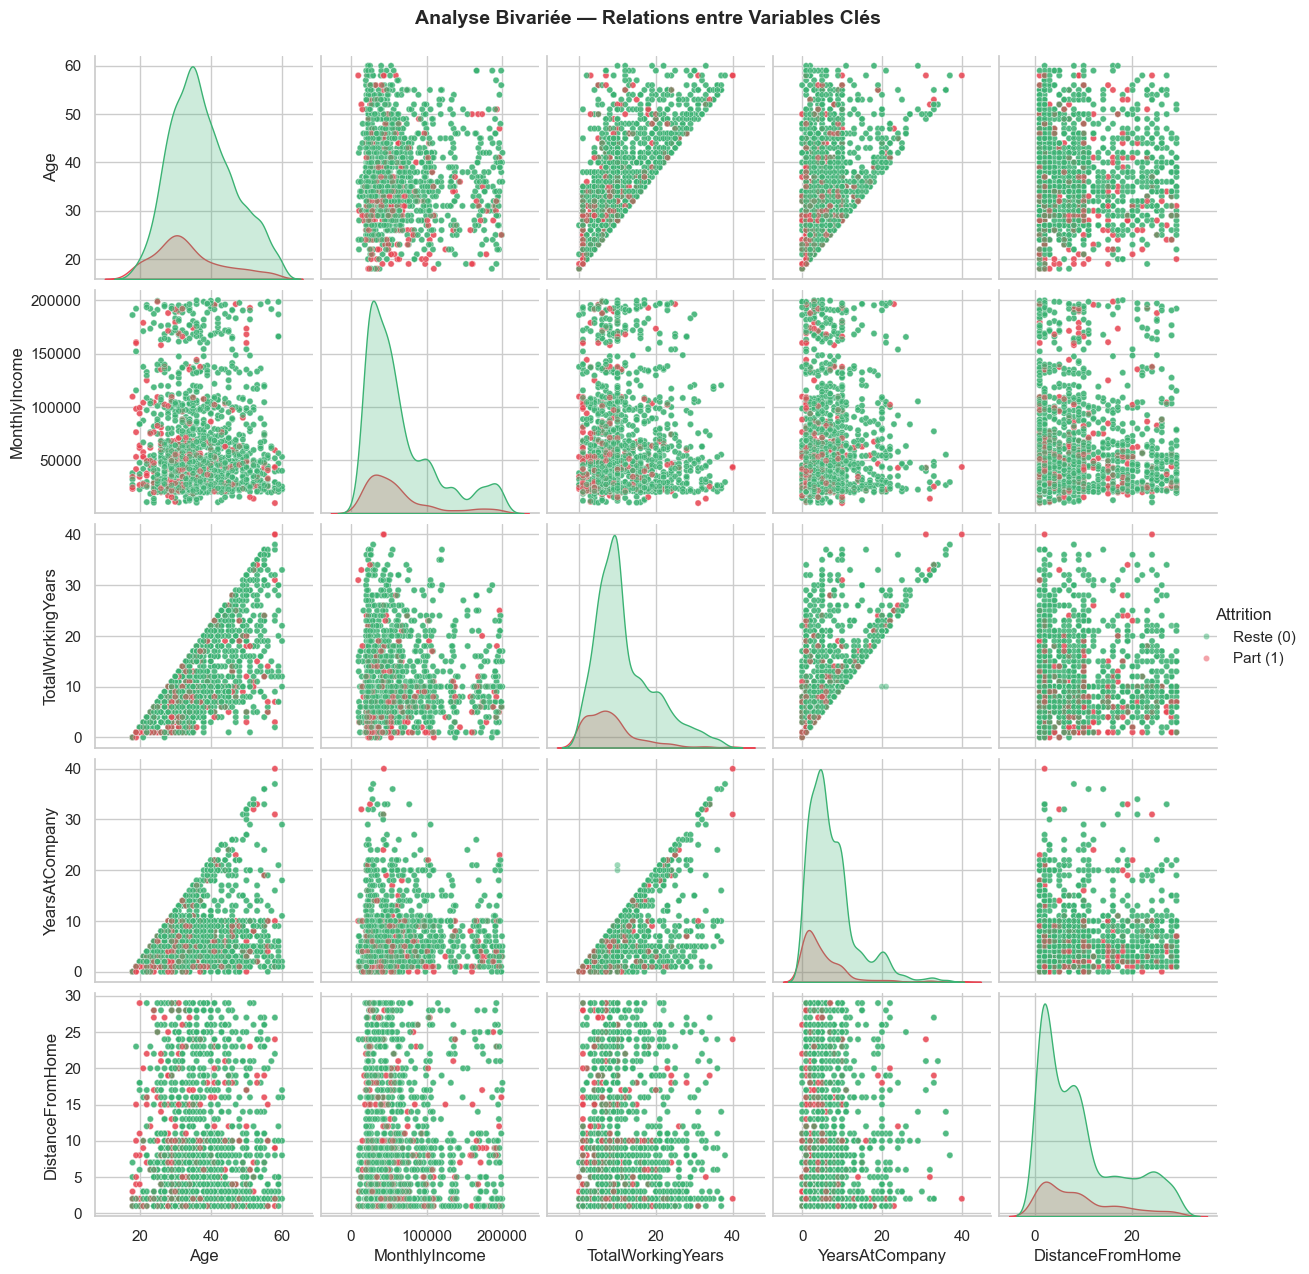

In [229]:
# ══════════════════════════════════════════════════════════════════════════════
# ANALYSE BIVARIÉE — PAIRPLOT
# ══════════════════════════════════════════════════════════════════════════════

# Sélection des variables clés pour le pairplot (limité pour la lisibilité)
pairplot_vars = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany', 'DistanceFromHome']
pairplot_vars = [c for c in pairplot_vars if c in df_clean.columns]

# Ajout de la variable cible pour colorer les points
df_pairplot = df_clean[pairplot_vars + ['Attrition']].copy()

print("Génération du pairplot (peut prendre quelques secondes)...")
g = sns.pairplot(df_pairplot, hue='Attrition', palette={0: COLORS['success'], 1: COLORS['danger']},
                 diag_kind='kde', plot_kws={'alpha': 0.5, 's': 20}, height=2.5)
g._legend.set_title('Attrition')
new_labels = ['Reste (0)', 'Part (1)']
for t, l in zip(g._legend.texts, new_labels):
    t.set_text(l)
plt.suptitle("Analyse Bivariée — Relations entre Variables Clés", fontsize=14, fontweight='bold', y=1.02)
plt.show()

### 4.6 Analyse par Boîtes à Moustache (Boxplots)

Les boîtes à moustache permettent de comparer la distribution des variables numériques entre les deux groupes (Attrition = 0 vs 1). Elles révèlent :
- La **médiane** (trait central)
- L'**intervalle interquartile** (boîte = 50% des données)
- Les **outliers** (points au-delà des moustaches)

Cette analyse permet d'identifier les variables discriminantes pour prédire l'attrition.

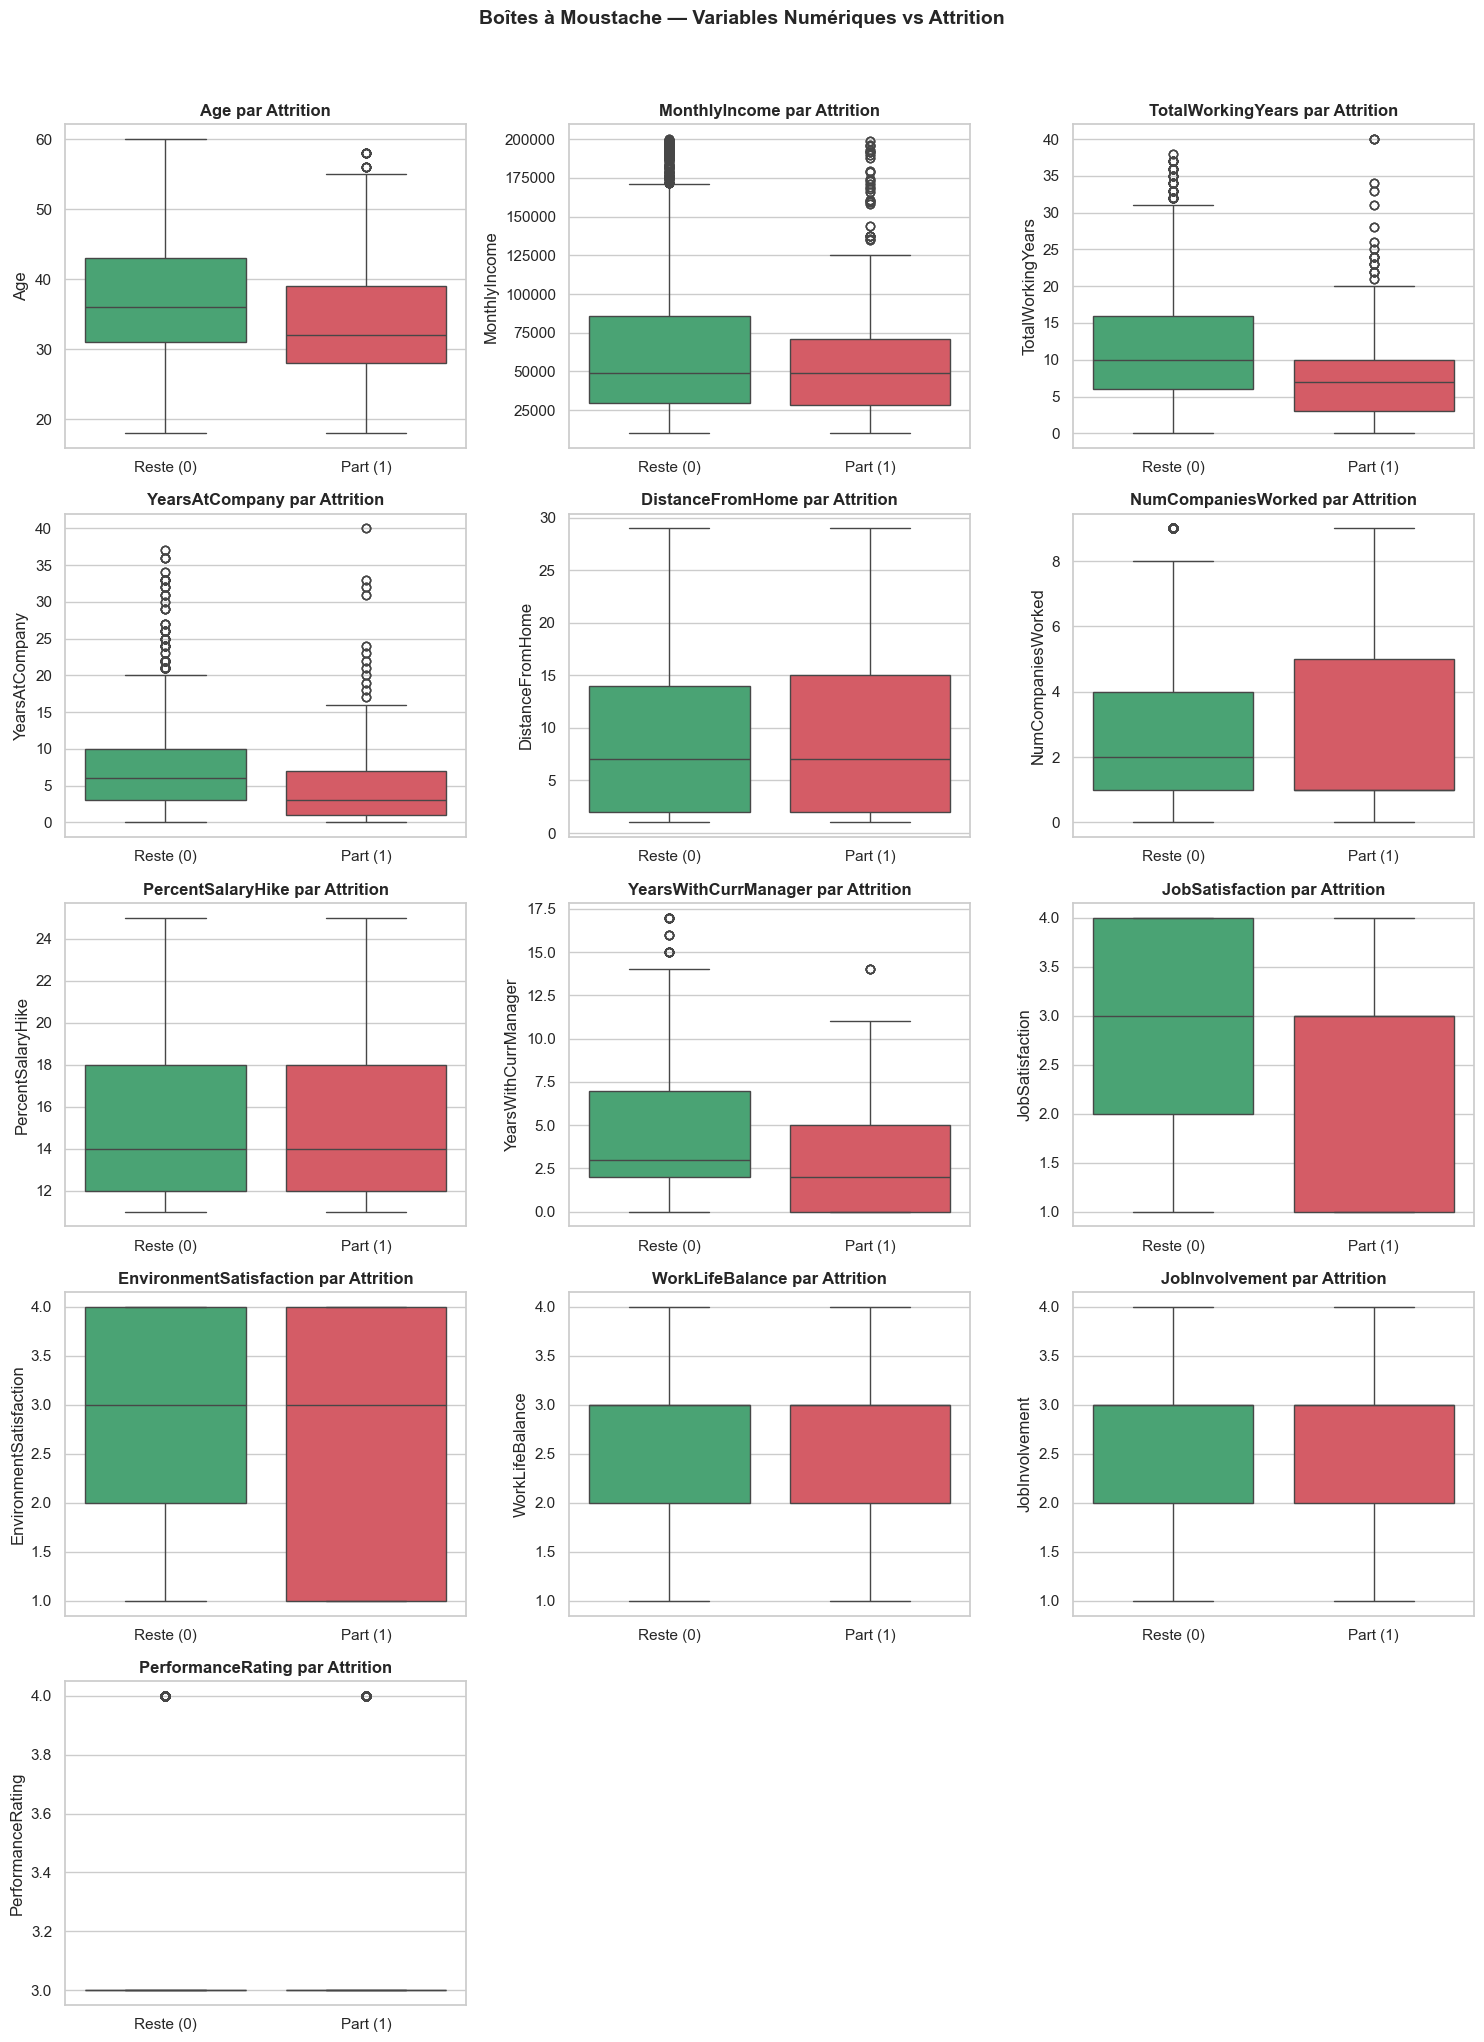

Résumé des médianes par groupe :
   Age                      : Reste=    36.0 | Part=    32.0 | 🔻 -11.1%
   MonthlyIncome            : Reste= 49300.0 | Part= 49080.0 | 🔻 -0.4%
   TotalWorkingYears        : Reste=    10.0 | Part=     7.0 | 🔻 -30.0%
   YearsAtCompany           : Reste=     6.0 | Part=     3.0 | 🔻 -50.0%
   DistanceFromHome         : Reste=     7.0 | Part=     7.0 | 🔻 +0.0%
   NumCompaniesWorked       : Reste=     2.0 | Part=     1.0 | 🔻 -50.0%
   PercentSalaryHike        : Reste=    14.0 | Part=    14.0 | 🔻 +0.0%
   YearsWithCurrManager     : Reste=     3.0 | Part=     2.0 | 🔻 -33.3%


In [230]:
# ══════════════════════════════════════════════════════════════════════════════
# ANALYSE PAR BOÎTES À MOUSTACHE — VARIABLES NUMÉRIQUES vs ATTRITION
# ══════════════════════════════════════════════════════════════════════════════

# Variables numériques à analyser
boxplot_vars = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
                'DistanceFromHome', 'NumCompaniesWorked', 'PercentSalaryHike',
                'YearsWithCurrManager', 'JobSatisfaction', 'EnvironmentSatisfaction',
                'WorkLifeBalance', 'JobInvolvement', 'PerformanceRating']

# Filtrer les colonnes disponibles
boxplot_vars = [c for c in boxplot_vars if c in df_clean.columns]

# Création de la grille
n_cols = 3
n_rows = (len(boxplot_vars) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for idx, col in enumerate(boxplot_vars):
    ax = axes[idx]
    sns.boxplot(x='Attrition', y=col, data=df_clean, ax=ax,
                palette={0: COLORS['success'], 1: COLORS['danger']}, hue='Attrition', legend=False)
    ax.set_xticklabels(['Reste (0)', 'Part (1)'])
    ax.set_title(f"{col} par Attrition", fontweight='bold')
    ax.set_xlabel("")

# Masquer les axes inutilisés
for idx in range(len(boxplot_vars), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Boîtes à Moustache — Variables Numériques vs Attrition", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Résumé des différences significatives
print("Résumé des médianes par groupe :")
print("=" * 60)
for col in boxplot_vars[:8]:  # Limiter l'affichage
    med_stay = df_clean[df_clean['Attrition'] == 0][col].median()
    med_leave = df_clean[df_clean['Attrition'] == 1][col].median()
    diff_pct = ((med_leave - med_stay) / med_stay * 100) if med_stay != 0 else 0
    sign = "🔺" if diff_pct > 0 else "🔻"
    print(f"   {col:25s}: Reste={med_stay:8.1f} | Part={med_leave:8.1f} | {sign} {diff_pct:+.1f}%")

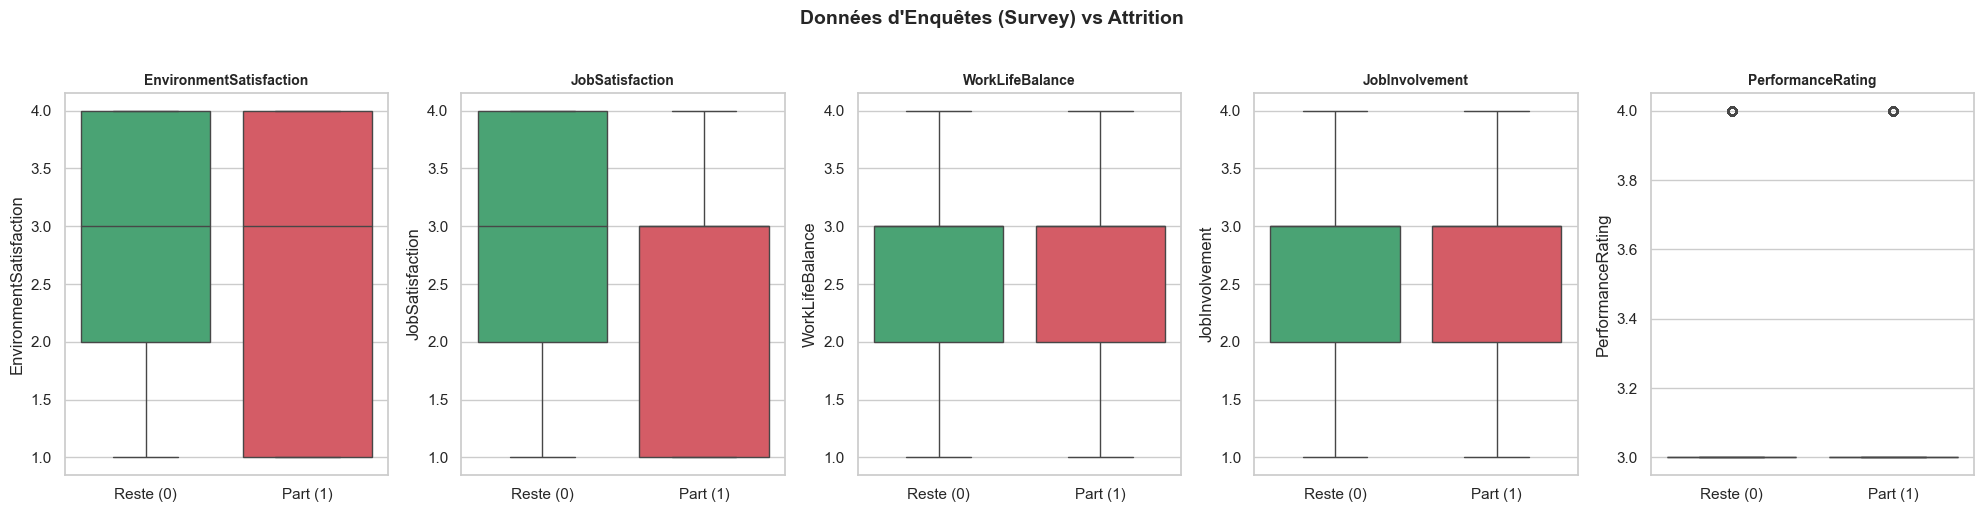

In [231]:
# ══════════════════════════════════════════════════════════════════════════════
# BOXPLOTS — VARIABLES DES ENQUÊTES (Survey Data)
# ══════════════════════════════════════════════════════════════════════════════

# Variables des enquêtes employés et managers
survey_vars = ['EnvironmentSatisfaction', 'JobSatisfaction', 'WorkLifeBalance',
               'JobInvolvement', 'PerformanceRating']
survey_vars = [c for c in survey_vars if c in df_clean.columns]

fig, axes = plt.subplots(1, len(survey_vars), figsize=(4 * len(survey_vars), 5))

for idx, col in enumerate(survey_vars):
    ax = axes[idx]
    sns.boxplot(x='Attrition', y=col, data=df_clean, ax=ax,
                palette={0: COLORS['success'], 1: COLORS['danger']}, hue='Attrition', legend=False)
    ax.set_xticklabels(['Reste (0)', 'Part (1)'])
    ax.set_title(f"{col}", fontweight='bold', fontsize=10)
    ax.set_xlabel("")

plt.suptitle("Données d'Enquêtes (Survey) vs Attrition", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

<a id="5"></a>
## 5. Analyse Exploratoire (EDA)

L'analyse exploratoire permet de :
1. Comprendre la distribution des variables
2. Identifier les corrélations avec la cible
3. Détecter les outliers et patterns

### 5.1 Distribution de la Variable Cible

**Déséquilibre des classes** : Le taux d'attrition est faible (~16%), ce qui crée un déséquilibre. Les métriques comme le F1-Score et l'AUC-ROC seront plus pertinentes que l'Accuracy.

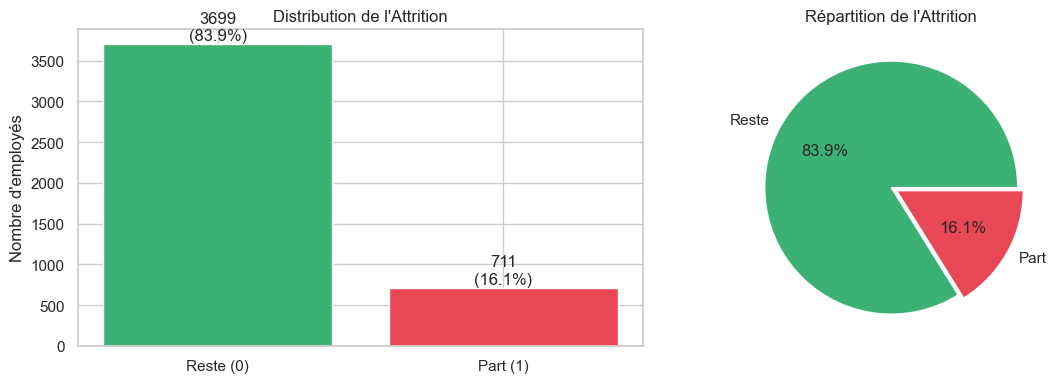

In [232]:
# Distribution de la cible
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Barplot
ax = axes[0]
counts = df_encoded['Attrition'].value_counts()
ax.bar(['Reste (0)', 'Part (1)'], counts.values, color=[COLORS['success'], COLORS['danger']])
ax.set_ylabel("Nombre d'employés")
ax.set_title("Distribution de l'Attrition")
for i, v in enumerate(counts.values):
    ax.text(i, v + 50, f"{v}\n({v/len(df_encoded)*100:.1f}%)", ha='center')

# Pie chart
ax = axes[1]
ax.pie(counts.values, labels=['Reste', 'Part'], autopct='%1.1f%%', 
       colors=[COLORS['success'], COLORS['danger']], explode=[0, 0.05])
ax.set_title("Répartition de l'Attrition")

plt.tight_layout()
plt.show()

### 5.2 Matrice de Corrélation

La corrélation de Pearson mesure la relation linéaire entre deux variables (-1 à +1).

**Interprétation** :
- Valeurs proches de +1 : forte corrélation positive
- Valeurs proches de -1 : forte corrélation négative
- Valeurs proches de 0 : pas de corrélation linéaire

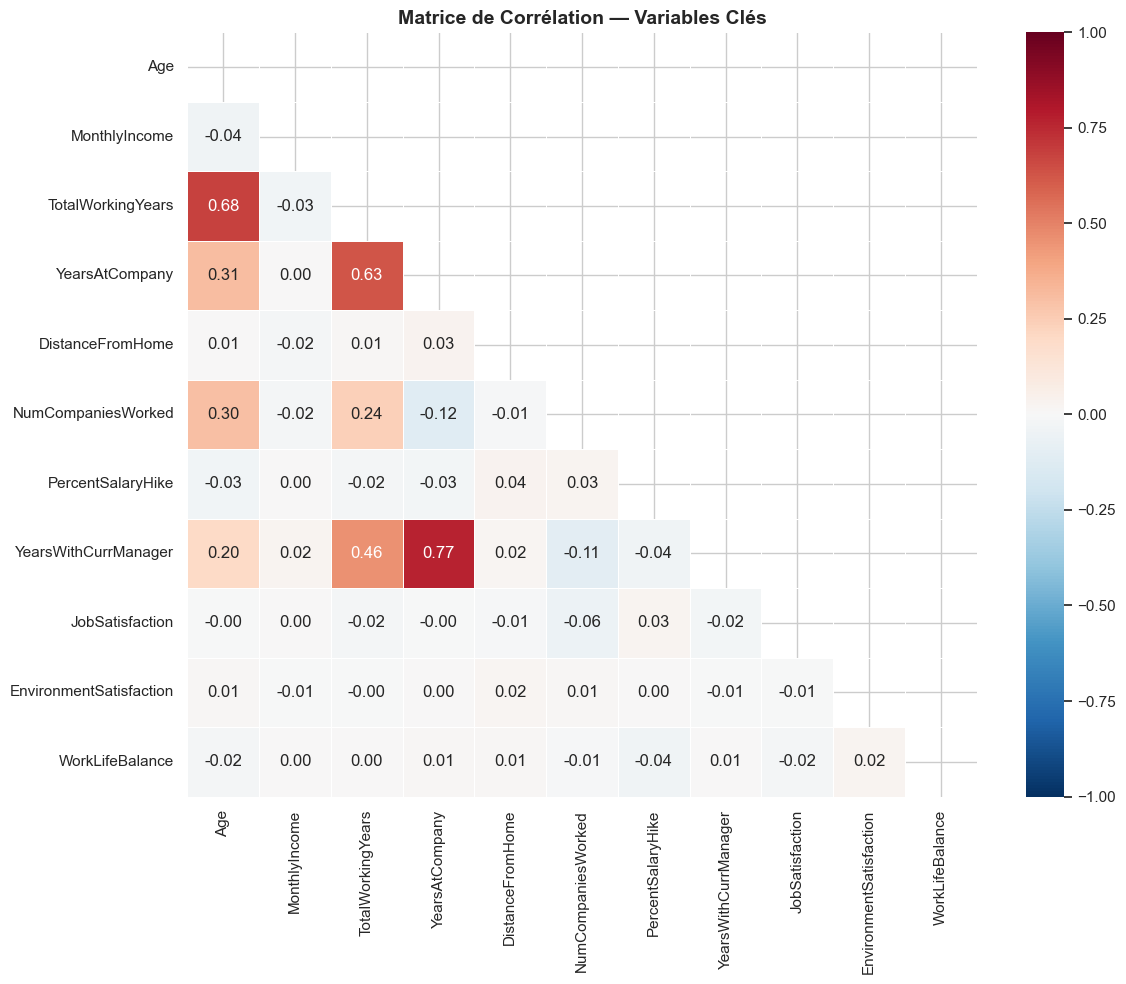

Top 10 corrélations avec Attrition :
   TotalWorkingYears             : -0.170
   Age                           : -0.159
   YearsWithCurrManager          : -0.156
   YearsAtCompany                : -0.134
   JobSatisfaction               : -0.103
   EnvironmentSatisfaction       : -0.102
   WorkLifeBalance               : -0.063
   NumCompaniesWorked            : +0.042
   PercentSalaryHike             : +0.033
   MonthlyIncome                 : -0.031


In [233]:
# Variables numériques principales pour la corrélation
key_num_cols = ['Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
                'DistanceFromHome', 'NumCompaniesWorked', 'PercentSalaryHike',
                'YearsWithCurrManager', 'JobSatisfaction', 'EnvironmentSatisfaction',
                'WorkLifeBalance', 'Attrition']

# Filtrer les colonnes disponibles
available_cols = [c for c in key_num_cols if c in df_encoded.columns]

# Calculer la matrice de corrélation complète (Attrition incluse pour l'analyse)
corr_matrix = df_encoded[available_cols].corr()

# Heatmap sans Attrition (variables entre elles uniquement)
heatmap_cols = [c for c in available_cols if c != 'Attrition']
heatmap_data = corr_matrix.loc[heatmap_cols, heatmap_cols]
mask = np.triu(np.ones_like(heatmap_data, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(heatmap_data, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matrice de Corrélation — Variables Clés", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top corrélations avec Attrition
corr_with_target = corr_matrix['Attrition'].drop('Attrition').sort_values(key=abs, ascending=False)
print("Top 10 corrélations avec Attrition :")
for var, corr in corr_with_target.head(10).items():
    sign = "+" if corr > 0 else ""
    print(f"   {var:30s}: {sign}{corr:.3f}")

<a id="6"></a>
## 6. Préparation pour le Machine Learning

### 6.1 Séparation Train / Test

On divise les données en deux ensembles :
- **Train (70%)** : pour entraîner les modèles
- **Test (30%)** : pour évaluer les performances sur des données jamais vues

Le paramètre `stratify=y` garantit que la proportion de classes est identique dans les deux ensembles.

### Option : Utiliser les Données Préparées (pour comparaison exacte)

Pour obtenir **exactement les mêmes résultats** que les fichiers individuels (02 à 08), il faut utiliser le fichier `prepared_data.csv` qui a été créé par `01_data_wrangling.ipynb` avec :
- Normalisation via `StandardScaler`
- Encodage via `OneHotEncoder`
- Variable `avg_working_time_seconds` incluse

Décommentez la cellule suivante si vous souhaitez utiliser les données préparées.

In [234]:
# ══════════════════════════════════════════════════════════════════════════════
# OPTION : CHARGER LES DONNÉES PRÉPARÉES (pour résultats identiques aux fichiers individuels)
# ══════════════════════════════════════════════════════════════════════════════

# Décommentez les lignes suivantes pour utiliser prepared_data.csv

USE_PREPARED_DATA = True  # Mettre à False pour utiliser les données calculées ci-dessus

if USE_PREPARED_DATA:
    print("Chargement des données préparées (prepared_data.csv)...")
    prepared_data = pd.read_csv('Data/prepared_data.csv')
    
    # Séparation features / cible
    X = prepared_data.drop(columns=['Attrition', 'EmployeeID'])
    y = prepared_data['Attrition']
    
    # Split train/test avec les MÊMES paramètres que les fichiers individuels
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42  # Même que les fichiers individuels
    )
    
    print(f"   Données préparées chargées : {X.shape[0]} lignes × {X.shape[1]} colonnes")
    print(f"   Train : {X_train.shape[0]} | Test : {X_test.shape[0]}")
    print(f"   Variable 'avg_working_time_seconds' présente : {'avg_working_time_seconds' in X.columns}")
else:
    print("Utilisation des données encodées calculées dans ce notebook")
    print("Les résultats peuvent différer des fichiers individuels")

Chargement des données préparées (prepared_data.csv)...
   Données préparées chargées : 4410 lignes × 45 colonnes
   Train : 3087 | Test : 1323
   Variable 'avg_working_time_seconds' présente : True


In [235]:
# Séparation features (X) et cible (y)
# Cette cellule n'est exécutée que si USE_PREPARED_DATA = False

if not USE_PREPARED_DATA:
    X = df_encoded.drop(columns=['Attrition', 'EmployeeID'])
    y = df_encoded['Attrition']

    # Split train/test avec stratification
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
    )

    print(f"   Séparation effectuée (données NON normalisées) :")
    print(f"   Train : {X_train.shape[0]} échantillons ({(1-TEST_SIZE)*100:.0f}%)")
    print(f"   Test  : {X_test.shape[0]} échantillons ({TEST_SIZE*100:.0f}%)")
    print(f"   Features : {X_train.shape[1]}")
    print(f"   Vérification de la stratification :")
    print(f"   Train - Attrition=1 : {y_train.mean()*100:.1f}%")
    print(f"   Test  - Attrition=1 : {y_test.mean()*100:.1f}%")
    print(f"   ATTENTION : Données non normalisées. Le SVM et autres modèles sensibles")
    print(f"   à l'échelle peuvent avoir des performances dégradées.")
else:
    print("    Utilisation des données préparées (prepared_data.csv) - déjà chargées")
    print(f"   Train : {X_train.shape[0]} | Test : {X_test.shape[0]} | Features : {X_train.shape[1]}")

    Utilisation des données préparées (prepared_data.csv) - déjà chargées
   Train : 3087 | Test : 1323 | Features : 45


### 6.2 Sauvegarde des Données Préparées (Optionnel)

Cette cellule permet de sauvegarder les données préparées pour une réutilisation ultérieure. Les données sont normalisées avec `StandardScaler` pour être cohérentes avec les autres notebooks du projet.

> **Note** : Si vous avez déjà exécuté `01_data_wrangling.ipynb`, les fichiers `prepared_data.csv` existent déjà.

In [236]:
# ══════════════════════════════════════════════════════════════════════════════
# SAUVEGARDE DES DONNÉES PRÉPARÉES (Optionnel)
# ══════════════════════════════════════════════════════════════════════════════

# Décommenter les lignes suivantes pour sauvegarder les données préparées

# # Normalisation des variables numériques avec StandardScaler
# scaler = StandardScaler()
# num_cols_for_scaling = df_encoded.select_dtypes(include=[np.number]).columns.drop(['Attrition', 'EmployeeID'])
# df_scaled = df_encoded.copy()
# df_scaled[num_cols_for_scaling] = scaler.fit_transform(df_encoded[num_cols_for_scaling])

# # Sauvegarde du dataset préparé
# df_scaled.to_csv('Data/prepared_data.csv', index=False)
# print("Données préparées sauvegardées dans Data/prepared_data.csv")

# # Sauvegarde sans les variables sensibles
# sensitive_cols_save = [c for c in df_scaled.columns if 'Gender' in c or 'MaritalStatus' in c]
# df_no_sensitive = df_scaled.drop(columns=sensitive_cols_save)
# df_no_sensitive.to_csv('Data/prepared_data_no_gender_marital_status.csv', index=False)
# print("Données sans Gender/MaritalStatus sauvegardées")

# # Sauvegarde des encoders et scaler
# with open('Data/scaler_final.pkl', 'wb') as f:
#     pickle.dump(scaler, f)
# with open('Data/label_encoder_final.pkl', 'wb') as f:
#     pickle.dump(le, f)
# print("Encoders sauvegardés")

print("Section de sauvegarde désactivée. Décommentez le code si nécessaire.")

Section de sauvegarde désactivée. Décommentez le code si nécessaire.


<a id="7"></a>
## 7. Modèles de Classification

Nous allons entraîner et comparer **7 algorithmes de classification**. Chaque algorithme a ses propres caractéristiques, avantages et inconvénients.

---

### 7.1 Rappels Théoriques des Algorithmes

#### Régression Logistique

La régression logistique est une technique statistique utilisée pour modéliser la probabilité qu'un événement binaire se produise. Elle repose sur une combinaison linéaire des variables explicatives transformée par la **fonction sigmoïde** :

$$z = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_n x_n$$

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

La probabilité que l'événement se produise ($y=1$) est alors :

$$P(y=1|x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \ldots + \beta_n x_n)}}$$

L’entraînement du modèle consiste à ajuster les coefficients $\beta$ en minimisant une fonction de coût (log-loss / entropie croisée), afin de produire les probabilités les plus cohérentes possibles avec les données observées.

Dans ce projet, la régression logistique est utilisée comme modèle de référence (baseline), car elle est rapide, robuste et interprétable.

**Avantages** : Interprétable, rapide, fournit des probabilités  
**Limitations** : Suppose une relation linéaire entre les variables et le log-odds

---

#### SVM (Support Vector Machine)

Le SVM (Support Vector Machine) est un algorithme de classification supervisée capable de séparer des classes à l’aide d’un hyperplan optimal. Dans ce projet, il permet de prédire si un employé risque de quitter l’entreprise (**Attrition = 1**) ou non (**Attrition = 0**) à partir de variables RH préparées.

Les Support Vector Machines (SVM) sont des modèles d’apprentissage supervisé utilisés principalement pour la classification, mais aussi dans certains cas pour la régression. Leur objectif est de trouver une frontière de décision (hyperplan) qui sépare au mieux les classes dans l’espace des caractéristiques.

L’idée centrale du SVM est de choisir l’hyperplan qui **maximise la marge de séparation**, c’est à dire la distance entre l’hyperplan et les points les plus proches de chaque classe. Ces points critiques sont appelés **vecteurs de support**.

Dans un problème de classification binaire, un hyperplan peut s’écrire sous la forme :

$$
\beta_0 + \beta_1 x_1 + \beta_2 x_2 + \ldots + \beta_n x_n = 0
$$

Le SVM cherche à maximiser la marge, ce qui revient à résoudre un problème d’optimisation visant à minimiser la norme des coefficients :

$$
\min \ \frac{1}{2}\|\beta\|^2
$$

Sous la contrainte de bonne séparation des données :

$$
y^{(i)} \left(\beta_0 + \beta_1 x_1^{(i)} + \beta_2 x_2^{(i)} + \ldots + \beta_n x_n^{(i)}\right) \geq 1
$$

Lorsque les données ne sont pas parfaitement séparables, on utilise une version à **marge souple (soft margin)**, qui autorise certaines erreurs de classification à l’aide de variables de relâchement $\xi_i$ :

$$
\min \ \frac{1}{2}\|\beta\|^2 + C \sum_{i=1}^{m}\xi_i
$$

Sous les contraintes :

$$
y^{(i)} \left(\beta_0 + \beta_1 x_1^{(i)} + \beta_2 x_2^{(i)} + \ldots + \beta_n x_n^{(i)}\right) \geq 1 - \xi_i
$$

$$
\xi_i \geq 0
$$

Le paramètre $C$ contrôle le compromis entre une grande marge et la pénalisation des erreurs de classification.

Pour traiter des relations non linéaires, le SVM peut utiliser des **noyaux (kernels)** qui projettent les données dans un espace de dimension plus élevée. Parmi les noyaux les plus courants, on trouve les noyaux linéaire, polynomial, RBF (radial) et sigmoïde.

Dans ce projet, le SVM est utilisé comme modèle de classification pour comparer ses performances à celles d’autres algorithmes sur la prédiction de l’attrition.

---

#### Perceptron

Le **Perceptron** est l'un des algorithmes d'apprentissage automatique les plus anciens et les plus fondamentaux, inventé par Frank Rosenblatt en 1957. Il s'agit d'un classificateur binaire linéaire, c'est-à-dire qu'il peut séparer deux classes de données en traçant une ligne (ou un hyperplan en dimensions supérieures) entre elles.

Le Perceptron est considéré comme la brique de base des réseaux de neurones modernes. Bien qu'il soit relativement simple, il pose les fondations conceptuelles pour comprendre les architectures plus complexes comme les réseaux de neurones profonds.

### Fonctionnement mathématique

Le Perceptron fonctionne selon les principes suivants :

1. **Combinaison linéaire** : Pour chaque observation, le modèle calcule une somme pondérée des caractéristiques :
   $$z = w_1x_1 + w_2x_2 + ... + w_nx_n + b = \mathbf{w}^T\mathbf{x} + b$$
   
   où :
   - $\mathbf{x} = (x_1, x_2, ..., x_n)$ sont les caractéristiques d'entrée
   - $\mathbf{w} = (w_1, w_2, ..., w_n)$ sont les poids appris
   - $b$ est le biais (intercept)

2. **Fonction d'activation** : Le résultat est ensuite passé à travers une fonction d'activation (signe) :
   $$\hat{y} = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$$

3. **Règle d'apprentissage** : Les poids sont mis à jour itérativement selon la règle :
   $$w_i := w_i + \eta \cdot (y - \hat{y}) \cdot x_i$$
   
   où $\eta$ est le taux d'apprentissage et $(y - \hat{y})$ est l'erreur de prédiction.

### Une image vaut mieux que trop de mots:

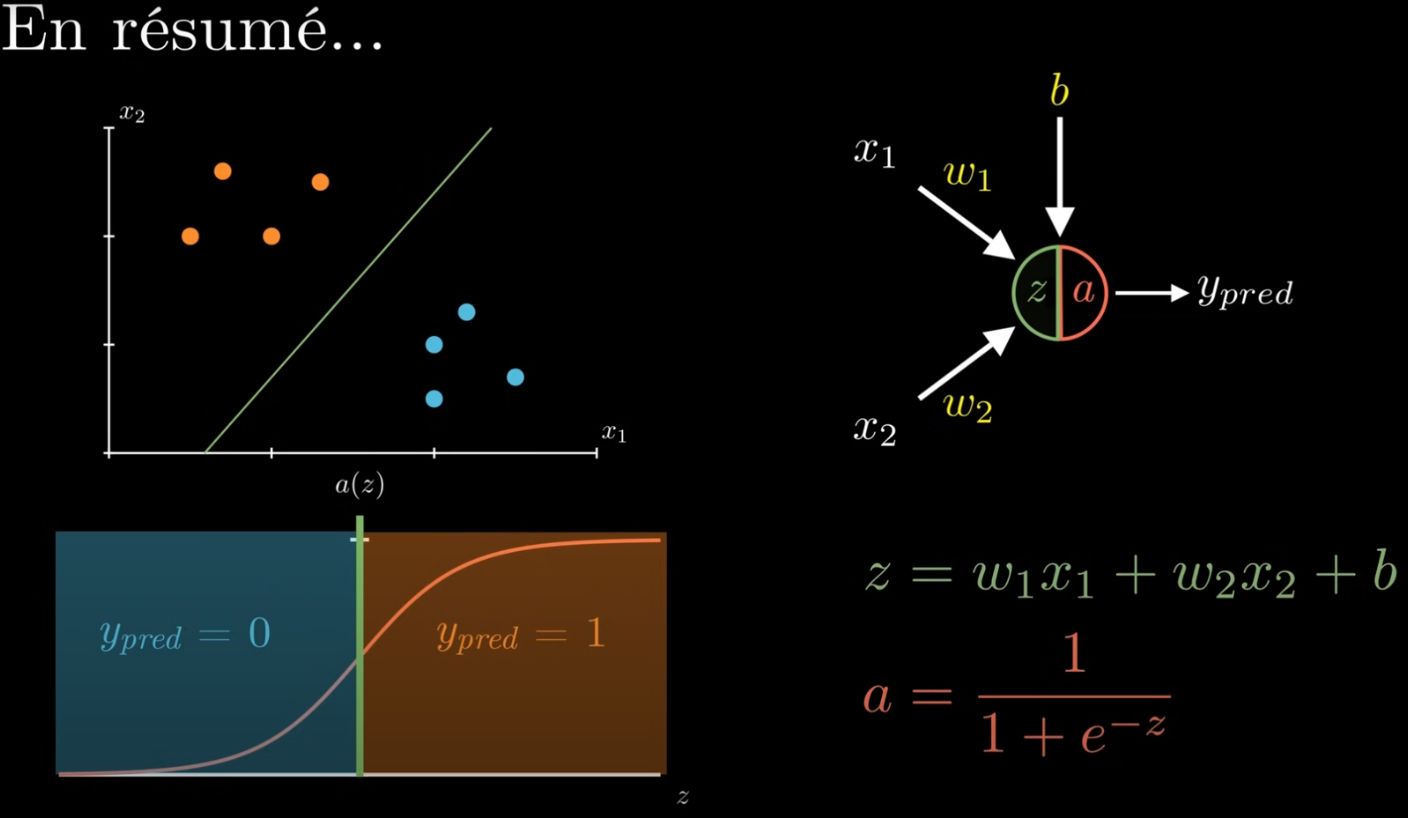

### Avantages du Perceptron

**Simplicité** : Algorithme facile à comprendre et à implémenter  
**Rapidité** : Entraînement très rapide, même sur de grands ensembles de données  
**Interprétabilité** : Les poids peuvent être interprétés directement  
**Efficacité mémoire** : Peu de paramètres à stocker  
**Adapté au temps réel** : Peut être mis à jour en ligne (online learning)

### Limitations

**Linéarité** : Ne peut classifier que des données linéairement séparables  
**Sensibilité** : Sensible aux valeurs aberrantes et à la normalisation  
**Pas de probabilités** : Ne fournit pas d'estimations probabilistes  
**Convergence** : Peut ne pas converger si les données ne sont pas linéairement séparables

### Application à la prédiction d'attrition

Dans notre contexte, nous utilisons le Perceptron pour prédire si un employé va quitter l'entreprise (attrition = 1) ou rester (attrition = 0). Le modèle apprendra à identifier une frontière de décision linéaire basée sur les caractéristiques des employés telles que :
- La satisfaction au travail
- Le niveau de salaire
- Les années dans l'entreprise
- L'équilibre vie professionnelle/vie privée
- Et autres facteurs démographiques et professionnels

---

#### Naive Bayes

Le Naive Bayes est une famille de classificateurs probabilistes basés sur l'application du théorème de Bayes avec une forte (naïve) hypothèse d'indépendance entre les caractéristiques. Il est particulièrement utile pour les grandes bases de données en raison de sa simplicité et de son efficacité computationnelle.

#### Principe de Fonctionnement

Le modèle Naive Bayes est basé sur le théorème de Bayes qui permet de calculer la probabilité d'une classe donnée un ensemble de caractéristiques. Le théorème de Bayes est exprimé comme suit :

$P(C_k | \mathbf{x}) = \frac{P(C_k) \cdot P(\mathbf{x} | C_k)}{P(\mathbf{x})}$

Où :
- $P(C_k | \mathbf{x})$ est la probabilité de la classe $C_k$ donnée les caractéristiques $\mathbf{x}$
- $P(C_k)$ est la probabilité a priori de la classe $C_k$
- $ P(\mathbf{x} | C_k) $ est la probabilité de $\mathbf{x}$ donnée la classe $ C_k $
- $ P(\mathbf{x}) $ est la probabilité de l'ensemble des caractéristiques $\mathbf{x} $

#### Hypothèse d'Indépendance

Le Naive Bayes fait l'hypothèse que les caractéristiques sont conditionnellement indépendantes les unes des autres, étant donné la classe :

$ P(\mathbf{x} | C_k) = \prod_{i=1}^{n} P(x_i | C_k) $

Cette hypothèse simplifie considérablement le calcul des probabilités et rend le modèle très efficace même avec un grand nombre de caractéristiques.

#### Types de Modèles Naive Bayes

Il existe plusieurs variantes du Naive Bayes en fonction du type de données :

- **Gaussian Naive Bayes** : Utilisé pour les caractéristiques continues et suppose que les caractéristiques suivent une distribution normale (gaussienne).
- **Multinomial Naive Bayes** : Utilisé pour les données discrètes, comme le comptage de mots dans le traitement du langage naturel.
- **Bernoulli Naive Bayes** : Utilisé pour les données binaires.

#### Fonction de Décision

Pour prédire la classe la plus probable pour un ensemble de caractéristiques, le Naive Bayes choisit la classe $ C_k $ qui maximise $ P(C_k | \mathbf{x}) $. En pratique, cela revient à choisir la classe qui maximise :

$ P(C_k) \cdot \prod_{i=1}^{n} P(x_i | C_k) $

#### Avantages et Inconvénients

##### Avantages :
- Simple à implémenter et très rapide à entraîner.
- Fonctionne bien avec des grands ensembles de données.
- Peu sensible aux données manquantes.
- Performant pour les problèmes de classification de texte et les systèmes de recommandation.

##### Inconvénients :
- L'hypothèse d'indépendance conditionnelle est souvent irréaliste dans les données réelles, ce qui peut affecter la précision du modèle.
- Ne prend pas en compte les interactions entre les caractéristiques.
- Les probabilités prédites peuvent être moins précises comparées à d'autres modèles de classification sophistiqués.

---

#### Arbre de Décision (Decision Tree)

Les arbres de décision sont des modèles de prédiction qui utilisent une structure d'arbre pour prendre des décisions basées sur des règles dérivées des caractéristiques des données. Ils sont largement utilisés pour les tâches de classification et de régression en raison de leur simplicité et de leur interprétabilité.

#### Principe de Fonctionnement

Un arbre de décision est constitué de nœuds de décision et de feuilles. Chaque nœud de décision représente une caractéristique des données, et chaque branche de ce nœud représente une valeur ou un intervalle de cette caractéristique. Les feuilles de l'arbre représentent les classes de sortie ou les valeurs de régression.

Le modèle divise de manière récursive les données en sous-ensembles basés sur les valeurs des caractéristiques, créant ainsi une structure en forme d'arbre. Le processus continue jusqu'à ce que tous les nœuds soient purs (c'est-à-dire qu'ils contiennent des instances d'une seule classe) ou qu'une condition d'arrêt soit atteinte.

#### Construction de l'Arbre

1. **Sélection de la Caractéristique** : À chaque nœud, le modèle sélectionne la caractéristique qui divise le mieux les données. Cela est généralement basé sur des critères comme la réduction de l'entropie ou la réduction de l'indice de Gini.
2. **Création de Nœuds** : Les données sont divisées en sous-ensembles basés sur la caractéristique sélectionnée, et des nœuds enfants sont créés pour chaque division.
3. **Répartition des Données** : Les sous-ensembles de données sont répartis entre les nœuds enfants, et le processus de sélection de la caractéristique se répète.
4. **Arrêt de la Division** : La division s'arrête lorsque tous les nœuds sont purs ou lorsqu'une condition d'arrêt prédéfinie est atteinte, comme une profondeur maximale de l'arbre ou un nombre minimal d'instances par nœud.

#### Critères de Sélection

- **Entropie et Gain d'Information** : L'entropie mesure le désordre dans les données. Le gain d'information est la réduction de l'entropie après la division des données.
- **Indice de Gini** : Mesure de l'impureté des données. Une valeur de 0 indique une pureté maximale, tandis qu'une valeur de 1 indique une impureté maximale.

#### Avantages et Inconvénients

##### Avantages :
- **Interprétabilité** : Les arbres de décision sont faciles à visualiser et à interpréter.
- **Pas de Prétraitement des Données** : Peuvent gérer des données numériques et catégoriques sans nécessiter de prétraitement.
- **Manipulation des Données Manquantes** : Peut gérer des valeurs manquantes en utilisant des mécanismes comme la pondération des chemins de décision.
- **Robustesse** : Peuvent capturer des interactions non linéaires entre les caractéristiques.

##### Inconvénients :
- **Surapprentissage** : Les arbres de décision peuvent facilement surapprendre les données d'entraînement, surtout lorsqu'ils sont profonds.
- **Variance Élevée** : Sensibles aux variations dans les données d'entraînement. Des changements mineurs peuvent entraîner des arbres complètement différents.
- **Biais** : Tendent à privilégier les caractéristiques avec de nombreuses valeurs distinctes.

#### Applications

- **Classification** : Attribution de classes à des instances basées sur leurs caractéristiques.
- **Régression** : Prédiction de valeurs continues.
- **Analyse Exploratoire** : Identification des caractéristiques importantes et des relations entre les caractéristiques et les classes de sortie.

---

#### Random Forest

Le **Random Forest** (Forêt Aléatoire) est un algorithme d'apprentissage supervisé puissant, introduit par Leo Breiman en 2001. Il s'agit d'une méthode d'**ensemble**, ce qui signifie qu'elle combine les prédictions de plusieurs modèles (ici, des arbres de décision) pour obtenir un résultat plus stable et précis.

Contrairement à un arbre de décision unique qui peut être instable et sujet au surapprentissage, la forêt utilise la "sagesse des foules" : en agrégeant les décisions de centaines d'arbres indépendants, elle réduit considérablement la variance du modèle global.

### Fonctionnement mathématique et logique

Le fonctionnement du Random Forest repose sur trois piliers fondamentaux :

1. **La brique de base : L'Arbre de Décision**
Chaque arbre divise les données en cherchant à maximiser la pureté des nœuds. On utilise généralement deux critères :
   - **Entropie** : L'entropie mesure le désordre dans les données. Le gain d'information est la réduction de l'entropie après la division des données.
   - **Indice de Gini** :  Mesure de l'impureté des données. Une valeur de 0 indique une pureté maximale, tandis qu'une valeur de 1 indique une impureté maximale.

2. **L'injection d'aléatoire (Bagging & Feature Selection)**
Pour que la forêt soit efficace, chaque arbre doit être différent. On introduit de l'aléatoire de deux manières :
   - **Bootstrap** : Chaque arbre est entraîné sur un échantillon aléatoire des données (tirage avec remplacement).
   - **Sous-espace aléatoire** : À chaque division (split), l'arbre ne choisit pas la meilleure variable parmi toutes, mais seulement parmi un sous-ensemble aléatoire de caractéristiques.

3. **Agrégation des prédictions**
Le résultat final $\hat{y}$ est obtenu en combinant les votes de tous les arbres :
   - **Classification** : Vote majoritaire (la classe la plus fréquente).
   - **Régression** : Moyenne arithmétique des prédictions de tous les arbres

### Avantages du Random Forest

**Réduction du Surapprentissage** : L'agrégation de nombreux arbres compense les erreurs individuelles.  
**Robustesse** : Très performant sur des données complexes, non-linéaires et avec des valeurs aberrantes.  
**Importance des variables** : Permet d'identifier quelles caractéristiques influencent le plus la prédiction.  
**Pas de normalisation** : Contrairement aux modèles linéaires (comme le Perceptron), il ne nécessite pas de mise à l'échelle des données.  
**Données manquantes** : Gère efficacement les valeurs absentes dans les jeux de données.

### Limitations

**Complexité** : L'entraînement de centaines d'arbres demande plus de ressources (mémoire et CPU).  
**Interprétabilité** : Moins visuel qu'un arbre unique (effet "boîte noire").  
**Vitesse** : La prédiction peut être plus lente en temps réel si la forêt contient un très grand nombre d'arbres.

---

#### 📘 k-NN (k-Nearest Neighbors)

Le **k-Nearest Neighbors (k-NN)** est l'un des algorithmes d'apprentissage automatique les plus simples et intuitifs. Il s'agit d'un algorithme de **classification non paramétrique** basé sur l'analogie : "Dis-moi qui sont tes voisins, et je te dirai qui tu es".

Contrairement aux modèles comme le Perceptron ou la Régression Logistique qui apprennent une frontière de décision explicite, le k-NN est un algorithme **basé sur les instances** (instance-based learning) : il mémorise l'ensemble d'entraînement et prend des décisions en comparant les nouvelles observations aux exemples connus.

### Principe fondamental

L'idée derrière k-NN est extrêmement simple :

> **"Un point appartient probablement à la même classe que ses voisins les plus proches"**

Pour classifier une nouvelle observation :
1. On calcule la **distance** entre cette observation et tous les points d'entraînement
2. On sélectionne les **k points les plus proches** (les k voisins)
3. On attribue la **classe majoritaire** parmi ces k voisins

### Calcul de distance

La mesure de similarité la plus couramment utilisée est la **distance euclidienne** :

$$d(\mathbf{x}_i, \mathbf{x}_j) = \sqrt{\sum_{p=1}^{n} (x_{i,p} - x_{j,p})^2}$$

où :
- $\mathbf{x}_i$ et $\mathbf{x}_j$ sont deux observations
- $n$ est le nombre de caractéristiques
- $x_{i,p}$ est la valeur de la caractéristique $p$ pour l'observation $i$

D'autres distances peuvent être utilisées : distance de Manhattan, distance de Minkowski, etc.

### Le paramètre k

Le choix de **k** (nombre de voisins) est crucial :

- **k = 1** : Classification très sensible au bruit (overfitting)
  - Avantage : Capture les patterns locaux
  - Inconvénient : Vulnérable aux outliers

- **k petit (3-5)** : Frontière de décision flexible
  - Capture les détails fins des données
  - Risque d'overfitting

- **k grand (>10)** : Frontière de décision plus lisse
  - Plus robuste au bruit
  - Risque d'underfitting

- **k = n** (tous les points) : Prédit toujours la classe majoritaire

**Règle empirique** : On choisit souvent $k = \sqrt{n}$ où $n$ est le nombre d'observations d'entraînement.

### Image explicative
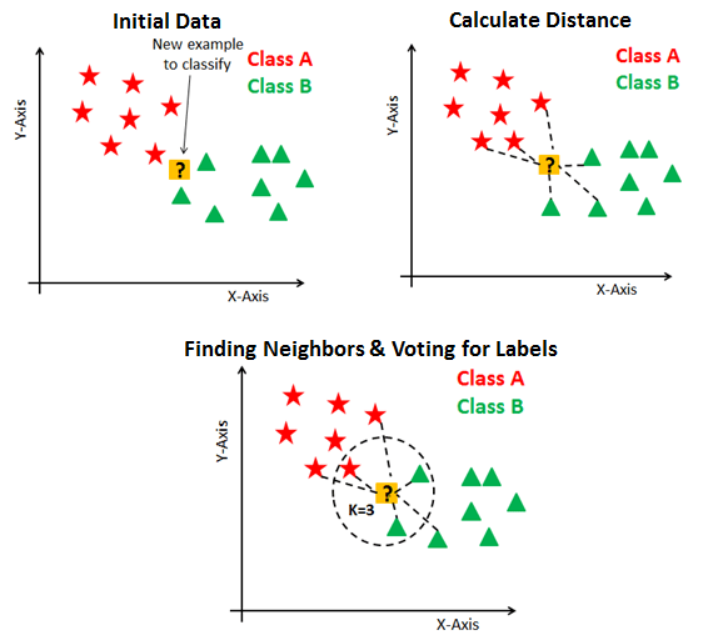

### Avantages du k-NN

**Simplicité** : Facile à comprendre et à implémenter  
**Non paramétrique** : Aucune hypothèse sur la distribution des données  
**Versatilité** : Fonctionne bien pour les données multi-classes  
**Adaptabilité** : Peut modéliser des frontières de décision complexes et non linéaires  
**Pas d'entraînement** : Pas de phase d'apprentissage à proprement parler  
**Probabilités** : Peut fournir des estimations probabilistes (% des k voisins)

### Limitations

**Coût computationnel** : Prédiction lente sur de grands ensembles (doit calculer toutes les distances)  
**Sensibilité à l'échelle** : Les caractéristiques avec de grandes valeurs dominent le calcul de distance  
**Malédiction de la dimensionnalité** : Performance dégradée avec beaucoup de features  
**Sensibilité au bruit** : Les outliers peuvent influencer les prédictions  
**Stockage** : Doit garder tout l'ensemble d'entraînement en mémoire  
**Déséquilibre des classes** : La classe majoritaire peut dominer

### Application à la prédiction d'attrition

Dans notre contexte, le k-NN va :
- Identifier les employés "similaires" dans l'espace multi-dimensionnel des caractéristiques
- Si les k employés les plus proches d'un nouvel employé sont majoritairement partis, on prédit un risque d'attrition élevé
- Si ses voisins sont restés, on prédit qu'il restera probablement

Par exemple, un employé avec :
- Faible satisfaction au travail
- Salaire bas
- Heures supplémentaires fréquentes
- Peu d'ancienneté

---

### 7.2 Tableau Récapitulatif

| Algorithme | Type | Forces | Faiblesses |
|------------|------|--------|------------|
| **Régression Logistique** | Linéaire | Interprétable, rapide | Suppose linéarité |
| **Perceptron** | Linéaire | Simple, rapide | Sensible au bruit |
| **SVM** | Non-linéaire | Efficace en haute dimension | Lent sur gros datasets |
| **Naive Bayes** | Probabiliste | Rapide, peu de données | Suppose indépendance |
| **Arbre de Décision** | Non-linéaire | Interprétable | Overfitting |
| **Random Forest** | Ensemble | Robuste, performant | Moins interprétable |
| **k-NN** | Instance-based | Simple, flexible | Lent en prédiction |

---

### 7.3 Métriques d'Évaluation (Section Commune)

Pour évaluer et comparer les modèles, nous utilisons plusieurs métriques complémentaires :

| Métrique | Formule | Interprétation |
|----------|---------|----------------|
| **Accuracy** | $\frac{TP + TN}{TP + TN + FP + FN}$ | % de prédictions correctes.  Attention au déséquilibre des classes ! |
| **Precision** | $\frac{TP}{TP + FP}$ | Parmi les prédits positifs, combien sont vrais ? (évite les faux positifs) |
| **Recall (Sensibilité)** | $\frac{TP}{TP + FN}$ | Parmi les vrais positifs, combien sont détectés ? (évite les faux négatifs) |
| **F1-Score** | $2 \times \frac{Precision \times Recall}{Precision + Recall}$ | Moyenne harmonique de Precision et Recall (équilibre les deux) |
| **AUC-ROC** | Aire sous la courbe ROC | Capacité à discriminer les classes (0.5 = aléatoire, 1 = parfait) |

**Où :**
- **TP (True Positives)** : Employés partants correctement prédits comme partants
- **TN (True Negatives)** : Employés restants correctement prédits comme restants
- **FP (False Positives)** : Employés restants prédits à tort comme partants
- **FN (False Negatives)** : Employés partants prédits à tort comme restants ( critiques en RH !)

**Choix de la métrique principale :**  
Dans un contexte de prédiction d'attrition, le **F1-Score** et l'**AUC-ROC** sont préférables à l'Accuracy car ils tiennent compte du déséquilibre des classes (~16% d'attrition seulement).

In [237]:
# ══════════════════════════════════════════════════════════════════════════════
# FONCTION COMMUNE : ENTRAÎNEMENT ET ÉVALUATION D'UN MODÈLE
# ══════════════════════════════════════════════════════════════════════════════

def train_and_evaluate(model, model_name, X_train, X_test, y_train, y_test):
    """
    Entraîne un modèle et retourne ses métriques de performance.
    
    Paramètres :
    - model : instance du modèle scikit-learn
    - model_name : nom du modèle (pour affichage)
    - X_train, X_test, y_train, y_test : données d'entraînement et de test
    
    Retourne :
    - dict avec les métriques (Accuracy, Precision, Recall, F1, AUC-ROC)
    - y_pred : prédictions sur le test set
    - y_proba : probabilités ou scores de décision (pour courbe ROC)
    - training_time : temps d'entraînement
    """
    # Entraînement
    start = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start
    
    # Prédictions
    y_pred = model.predict(X_test)
    
    # Probabilités ou scores de décision
    if hasattr(model, "predict_proba"):
        # Modèles avec probabilités (Logistic, SVM, NB, Trees, RF, kNN)
        y_proba = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        # Modèles avec decision_function (Perceptron, SVM sans probability=True)
        y_proba = model.decision_function(X_test)
    else:
        # Fallback : utiliser les prédictions (déconseillé)
        y_proba = y_pred
    
    # Métriques
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'AUC-ROC': roc_auc_score(y_test, y_proba)
    }
    
    return metrics, y_pred, y_proba, training_time

print("Fonction d'évaluation définie")

Fonction d'évaluation définie


In [238]:
# ══════════════════════════════════════════════════════════════════════════════
# DÉFINITION DES 7 MODÈLES (nouvelles instances à chaque exécution)
# ══════════════════════════════════════════════════════════════════════════════

# Utiliser des fonctions lambda pour créer de nouvelles instances à chaque appel
# Cela évite les problèmes de réutilisation d'instances déjà entraînées

def get_models():
    """Retourne un dictionnaire de nouvelles instances de modèles."""
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'Perceptron': Perceptron(max_iter=1000, random_state=42),
        'SVM': SVC(probability=True, random_state=42),
        'Naive Bayes': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
        'k-NN': KNeighborsClassifier(n_neighbors=5)
    }

# Créer les instances
models = get_models()

print(f"{len(models)} modèles définis (nouvelles instances)")
print("   Paramètres identiques aux fichiers individuels (random_state=42)")

7 modèles définis (nouvelles instances)
   Paramètres identiques aux fichiers individuels (random_state=42)


In [239]:
# ══════════════════════════════════════════════════════════════════════════════
# ENTRAÎNEMENT DE TOUS LES MODÈLES
# ══════════════════════════════════════════════════════════════════════════════

all_metrics = []
all_predictions = {}
all_probabilities = {}
training_times = {}

print("Entraînement des modèles en cours...\n")

for name, model in models.items():
    metrics, y_pred, y_proba, t_time = train_and_evaluate(
        model, name, X_train, X_test, y_train, y_test
    )
    
    all_metrics.append(metrics)
    all_predictions[name] = y_pred
    all_probabilities[name] = y_proba
    training_times[name] = t_time
    
    print(f"✓ {name:22s} | Acc: {metrics['Accuracy']:.4f} | F1: {metrics['F1 Score']:.4f} | AUC: {metrics['AUC-ROC']:.4f} | {t_time:.3f}s")

# Créer le DataFrame des résultats
metrics_df = pd.DataFrame(all_metrics).round(4)
print("Tous les modèles entraînés !")

Entraînement des modèles en cours...

✓ Logistic Regression    | Acc: 0.8587 | F1: 0.3869 | AUC: 0.8024 | 0.014s
✓ Perceptron             | Acc: 0.8186 | F1: 0.3617 | AUC: 0.7105 | 0.004s
✓ SVM                    | Acc: 0.9123 | F1: 0.6306 | AUC: 0.9225 | 0.609s
✓ Naive Bayes            | Acc: 0.8027 | F1: 0.4055 | AUC: 0.7398 | 0.019s
✓ Decision Tree          | Acc: 0.9705 | F1: 0.9051 | AUC: 0.9395 | 0.013s
✓ Random Forest          | Acc: 0.9834 | F1: 0.9442 | AUC: 0.9949 | 0.279s
✓ k-NN                   | Acc: 0.8284 | F1: 0.3606 | AUC: 0.8383 | 0.000s
Tous les modèles entraînés !


### 7.3 Sauvegarde des Modèles et Résultats

Chaque modèle est sauvegardé avec ses résultats (prédictions, probabilités, matrice de confusion) dans un fichier `.pkl` dédié. Cela permet de :
- Réutiliser les modèles sans réentraînement
- Comparer les résultats avec d'autres analyses
- Assurer la reproductibilité des expériences

In [240]:
# ══════════════════════════════════════════════════════════════════════════════
# SAUVEGARDE DES MODÈLES ET RÉSULTATS
# ══════════════════════════════════════════════════════════════════════════════

import os

# Mapping des noms de modèles vers les noms de fichiers
model_file_mapping = {
    'Logistic Regression': 'logistic_regression',
    'Perceptron': 'perceptron',
    'SVM': 'svm',
    'Naive Bayes': 'naive_bayes',
    'Decision Tree': 'decision_tree',
    'Random Forest': 'random_forest',
    'k-NN': 'knn'
}

print("Sauvegarde des modèles et résultats...")
print("=" * 60)

for name, model in models.items():
    # Calculer la matrice de confusion
    y_pred = all_predictions[name]
    y_proba = all_probabilities[name]
    cm = confusion_matrix(y_test, y_pred)
    
    # Préparer les résultats
    results = {
        'model': model,
        'predictions': y_pred,
        'probabilities': y_proba,
        'confusion_matrix': cm,
        'y_test': y_test.values,
        'accuracy': accuracy_score(y_test, y_pred),
        'f1_score': f1_score(y_test, y_pred),
        'auc_roc': roc_auc_score(y_test, y_proba) if y_proba is not None else None,
        'classification_report': classification_report(y_test, y_pred, output_dict=True),
        'training_time': training_times[name]
    }
    
    # Nom du fichier
    file_prefix = model_file_mapping[name]
    
    # Sauvegarder le modèle seul (comme dans les fichiers individuels)
    model_path = f'Data/{file_prefix}_model.pkl'
    with open(model_path, 'wb') as f:
        pickle.dump(model, f)
    
    # Sauvegarder les résultats complets
    results_path = f'Data/{file_prefix}_results.pkl'
    with open(results_path, 'wb') as f:
        pickle.dump(results, f)
    
    TN, FP, FN, TP = cm.ravel()
    print(f"✓ {name:22s} → {file_prefix}_model.pkl + {file_prefix}_results.pkl")
    print(f"  └─ CM: TN={TN}, FP={FP}, FN={FN}, TP={TP}")

print("=" * 60)
print("Tous les modèles et résultats sauvegardés dans Data/")

Sauvegarde des modèles et résultats...
✓ Logistic Regression    → logistic_regression_model.pkl + logistic_regression_results.pkl
  └─ CM: TN=1077, FP=38, FN=149, TP=59
✓ Perceptron             → perceptron_model.pkl + perceptron_results.pkl
  └─ CM: TN=1015, FP=100, FN=140, TP=68
✓ SVM                    → svm_model.pkl + svm_results.pkl
  └─ CM: TN=1108, FP=7, FN=109, TP=99
✓ Naive Bayes            → naive_bayes_model.pkl + naive_bayes_results.pkl
  └─ CM: TN=973, FP=142, FN=119, TP=89
✓ Decision Tree          → decision_tree_model.pkl + decision_tree_results.pkl
  └─ CM: TN=1098, FP=17, FN=22, TP=186
✓ Random Forest          → random_forest_model.pkl + random_forest_results.pkl
  └─ CM: TN=1115, FP=0, FN=22, TP=186
✓ k-NN                   → knn_model.pkl + knn_results.pkl
  └─ CM: TN=1032, FP=83, FN=144, TP=64
Tous les modèles et résultats sauvegardés dans Data/


### 7.4 Matrices de Confusion par Modèle

La matrice de confusion permet de visualiser les performances de chaque modèle en détail :
- **TN (True Negatives)** : employés restants correctement identifiés
- **FP (False Positives)** : fausses alertes (employés restants prédits comme partants)
- **FN (False Negatives)** : employés partants non détectés (critiques en RH)
- **TP (True Positives)** : employés partants correctement détectés

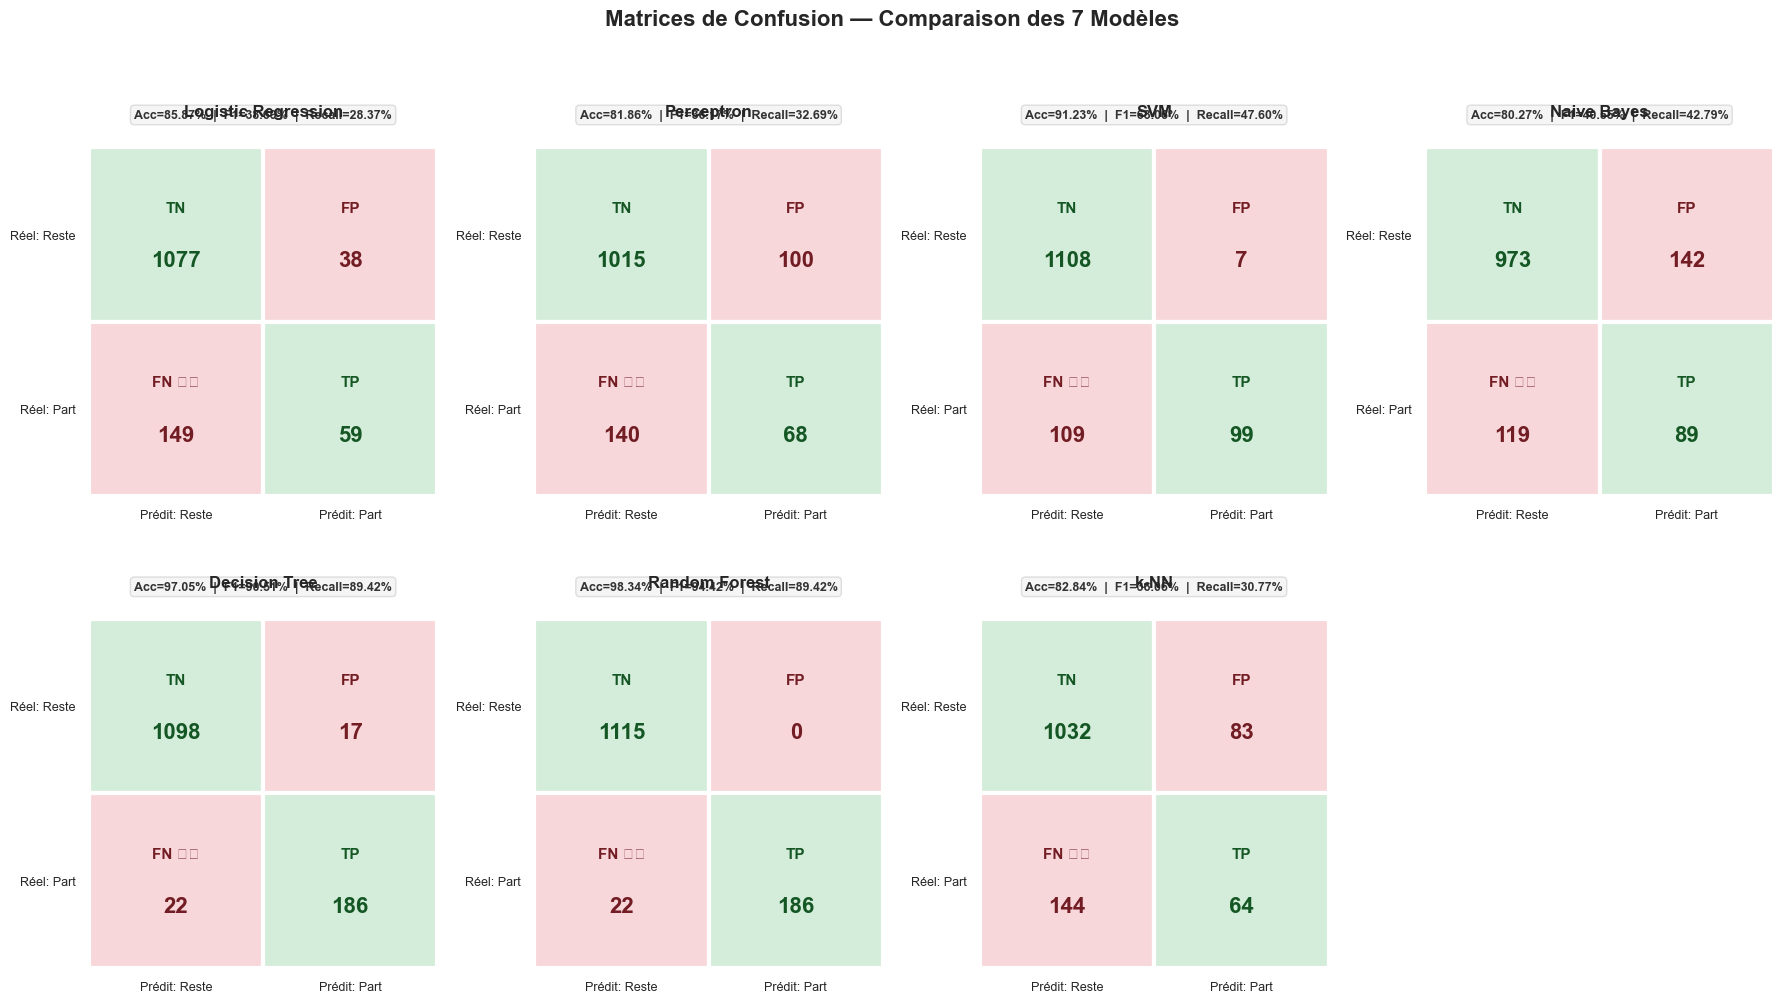


══════════════════════════════════════════════════════════════════════════════════════════
RÉCAPITULATIF DES PERFORMANCES PAR MODÈLE
══════════════════════════════════════════════════════════════════════════════════════════
Modèle                    │     TN │     FP │     FN │     TP │   Recall │       F1
──────────────────────────────────────────────────────────────────────────────────────────
1 Random Forest           │   1115 │      0 │     22 │    186 │    89.4% │    94.4%
  Decision Tree           │   1098 │     17 │     22 │    186 │    89.4% │    90.5%
  SVM                     │   1108 │      7 │    109 │     99 │    47.6% │    63.1%
  Naive Bayes             │    973 │    142 │    119 │     89 │    42.8% │    40.5%
  Logistic Regression     │   1077 │     38 │    149 │     59 │    28.4% │    38.7%
  Perceptron              │   1015 │    100 │    140 │     68 │    32.7% │    36.2%
  k-NN                    │   1032 │     83 │    144 │     64 │    30.8% │    36.1%
────────────

In [241]:
# ══════════════════════════════════════════════════════════════════════════════
# MATRICES DE CONFUSION POUR TOUS LES MODÈLES
# ══════════════════════════════════════════════════════════════════════════════

n_models = len(models)
n_cols = 4
n_rows = (n_models + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
axes = axes.flatten()

# Couleurs personnalisées pour un meilleur contraste
colors_cm = {
    'TN': {'bg': '#d4edda', 'text': '#155724'},  # Vert clair / vert foncé
    'TP': {'bg': '#d4edda', 'text': '#155724'},  # Vert clair / vert foncé  
    'FP': {'bg': '#f8d7da', 'text': '#721c24'},  # Rouge clair / rouge foncé
    'FN': {'bg': '#f8d7da', 'text': '#721c24'}   # Rouge clair / rouge foncé
}

for idx, (name, y_pred) in enumerate(all_predictions.items()):
    ax = axes[idx]
    cm = confusion_matrix(y_test, y_pred)
    TN, FP, FN, TP = cm.ravel()
    
    # Calcul des métriques
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    
    # Créer une matrice avec les pourcentages
    total = cm.sum()
    
    # Dessiner les 4 cases manuellement avec des couleurs distinctes
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2)
    
    # Case TN (haut gauche)
    rect_tn = plt.Rectangle((0, 1), 1, 1, facecolor=colors_cm['TN']['bg'], edgecolor='white', linewidth=3)
    ax.add_patch(rect_tn)
    ax.text(0.5, 1.65, 'TN', ha='center', va='center', fontsize=11, fontweight='bold', color=colors_cm['TN']['text'])
    ax.text(0.5, 1.35, f'{TN}', ha='center', va='center', fontsize=16, fontweight='bold', color=colors_cm['TN']['text'])
    
    # Case FP (haut droite)
    rect_fp = plt.Rectangle((1, 1), 1, 1, facecolor=colors_cm['FP']['bg'], edgecolor='white', linewidth=3)
    ax.add_patch(rect_fp)
    ax.text(1.5, 1.65, 'FP', ha='center', va='center', fontsize=11, fontweight='bold', color=colors_cm['FP']['text'])
    ax.text(1.5, 1.35, f'{FP}', ha='center', va='center', fontsize=16, fontweight='bold', color=colors_cm['FP']['text'])
    
    # Case FN (bas gauche) - CRITIQUE
    rect_fn = plt.Rectangle((0, 0), 1, 1, facecolor=colors_cm['FN']['bg'], edgecolor='white', linewidth=3)
    ax.add_patch(rect_fn)
    ax.text(0.5, 0.65, 'FN ⚠️', ha='center', va='center', fontsize=11, fontweight='bold', color=colors_cm['FN']['text'])
    ax.text(0.5, 0.35, f'{FN}', ha='center', va='center', fontsize=16, fontweight='bold', color=colors_cm['FN']['text'])
    
    # Case TP (bas droite)
    rect_tp = plt.Rectangle((1, 0), 1, 1, facecolor=colors_cm['TP']['bg'], edgecolor='white', linewidth=3)
    ax.add_patch(rect_tp)
    ax.text(1.5, 0.65, 'TP', ha='center', va='center', fontsize=11, fontweight='bold', color=colors_cm['TP']['text'])
    ax.text(1.5, 0.35, f'{TP}', ha='center', va='center', fontsize=16, fontweight='bold', color=colors_cm['TP']['text'])
    
    # Labels des axes
    ax.set_xticks([0.5, 1.5])
    ax.set_xticklabels(['Prédit: Reste', 'Prédit: Part'], fontsize=9)
    ax.set_yticks([0.5, 1.5])
    ax.set_yticklabels(['Réel: Part', 'Réel: Reste'], fontsize=9)
    
    # Titre avec métriques
    title_color = '#2e7d32' if f1 > 0.5 else '#c62828'
    ax.set_title(f'{name}\n', fontsize=12, fontweight='bold', pad=10)
    
    # Ajouter les métriques sous forme de badges
    metrics_text = f'Acc={acc:.2%}  |  F1={f1:.2%}  |  Recall={recall:.2%}'
    ax.text(1, 2.15, metrics_text, ha='center', va='bottom', fontsize=9, 
            color='#333', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#f5f5f5', edgecolor='#ddd'))
    
    ax.set_aspect('equal')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)

# Masquer les axes inutilisés
for idx in range(n_models, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Matrices de Confusion — Comparaison des 7 Modèles", 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Tableau récapitulatif amélioré
print("\n" + "═" * 90)
print("RÉCAPITULATIF DES PERFORMANCES PAR MODÈLE")
print("═" * 90)
print(f"{'Modèle':25s} │ {'TN':>6s} │ {'FP':>6s} │ {'FN':>6s} │ {'TP':>6s} │ {'Recall':>8s} │ {'F1':>8s}")
print("─" * 90)

# Trier par F1 score décroissant
sorted_models = sorted(all_predictions.items(), 
                       key=lambda x: f1_score(y_test, x[1]), reverse=True)

for name, y_pred in sorted_models:
    cm = confusion_matrix(y_test, y_pred)
    TN, FP, FN, TP = cm.ravel()
    recall = TP / (TP + FN) * 100 if (TP + FN) > 0 else 0
    f1 = f1_score(y_test, y_pred) * 100
    
    # Indicateur visuel
    indicator = "1 " if f1 == max(f1_score(y_test, p) * 100 for p in all_predictions.values()) else "  "
    
    print(f"{indicator}{name:23s} │ {TN:6d} │ {FP:6d} │ {FN:6d} │ {TP:6d} │ {recall:7.1f}% │ {f1:7.1f}%")

print("─" * 90)
print("FN (Faux Négatifs) = Départs non détectés → À MINIMISER en RH")
print("Meilleur modèle selon le F1 Score")
print("═" * 90)

### 7.5 Feature Importance par Modèle

Certains modèles permettent d'extraire l'importance des variables :
- **Régression Logistique** : coefficients (valeur absolue)
- **Arbre de Décision / Random Forest** : importance basée sur la réduction de l'impureté (Gini)
- **Perceptron** : coefficients (valeur absolue)
- **SVM, Naive Bayes, k-NN** : n'ont pas de feature importance directe

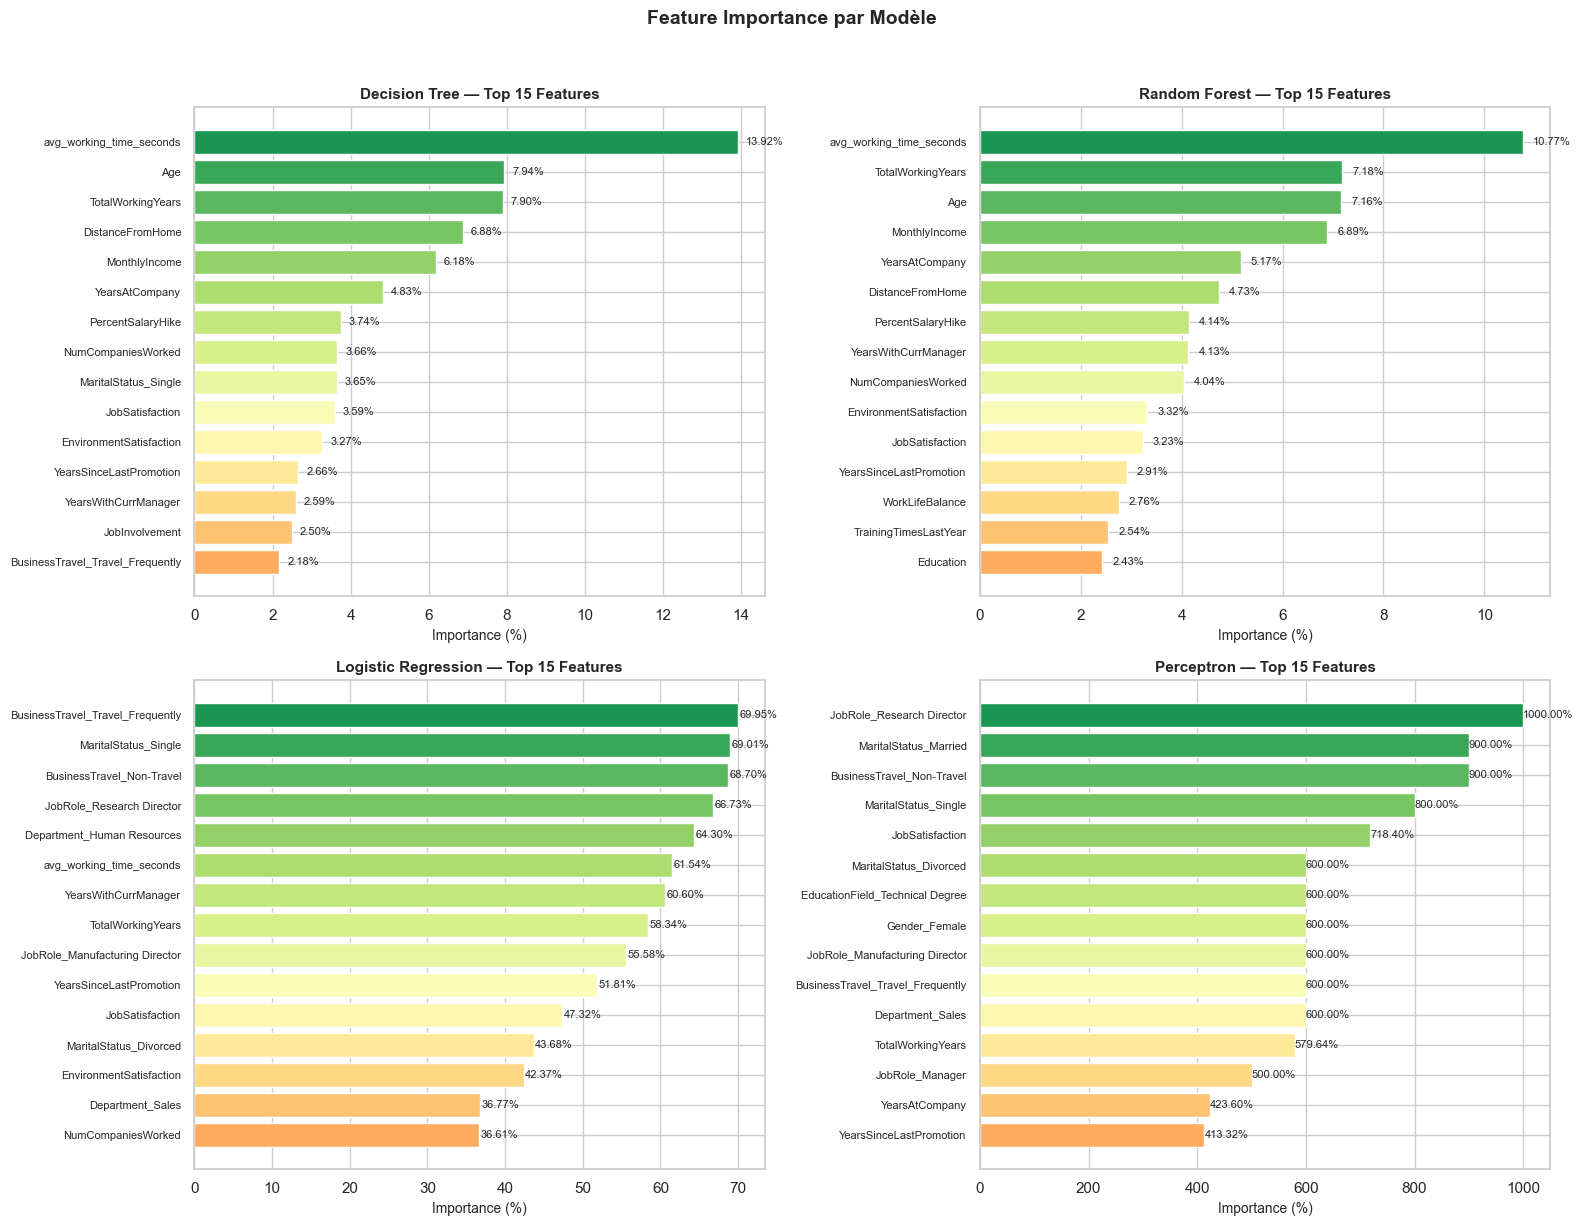

Top 5 Features par Modèle :

 - Decision Tree:
   avg_working_time_seconds           : 13.92%
   Age                                : 7.94%
   TotalWorkingYears                  : 7.90%
   DistanceFromHome                   : 6.88%
   MonthlyIncome                      : 6.18%

 - Random Forest:
   avg_working_time_seconds           : 10.77%
   TotalWorkingYears                  : 7.18%
   Age                                : 7.16%
   MonthlyIncome                      : 6.89%
   YearsAtCompany                     : 5.17%

 - Logistic Regression:
   BusinessTravel_Travel_Frequently   : 69.95%
   MaritalStatus_Single               : 69.01%
   BusinessTravel_Non-Travel          : 68.70%
   JobRole_Research Director          : 66.73%
   Department_Human Resources         : 64.30%

 - Perceptron:
   JobRole_Research Director          : 1000.00%
   BusinessTravel_Non-Travel          : 900.00%
   MaritalStatus_Married              : 900.00%
   MaritalStatus_Single               : 800.00%
   

In [242]:
# ══════════════════════════════════════════════════════════════════════════════
# FEATURE IMPORTANCE POUR LES MODÈLES QUI LE SUPPORTENT
# ══════════════════════════════════════════════════════════════════════════════

# Dictionnaire pour stocker les feature importances
feature_importances_all = {}
TOP_FEATURES = 15

# Modèles avec feature_importances_ (arbres)
tree_models = ['Decision Tree', 'Random Forest']
for name in tree_models:
    model = models[name]
    fi = pd.DataFrame({
        'feature': X.columns,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False)
    feature_importances_all[name] = fi

# Modèles avec coef_ (linéaires)
linear_models = ['Logistic Regression', 'Perceptron']
for name in linear_models:
    model = models[name]
    fi = pd.DataFrame({
        'feature': X.columns,
        'importance': np.abs(model.coef_[0])  # Valeur absolue des coefficients
    }).sort_values('importance', ascending=False)
    feature_importances_all[name] = fi

# Visualisation comparative
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, (name, fi) in enumerate(feature_importances_all.items()):
    ax = axes[idx]
    top_fi = fi.head(TOP_FEATURES).sort_values('importance')
    
    # Couleurs en dégradé
    colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, TOP_FEATURES))
    
    bars = ax.barh(top_fi['feature'], top_fi['importance'] * 100, color=colors)
    
    for bar, val in zip(bars, top_fi['importance'] * 100):
        ax.text(val + 0.2, bar.get_y() + bar.get_height()/2, f"{val:.2f}%", 
                va='center', fontsize=8)
    
    ax.set_xlabel("Importance (%)", fontsize=10)
    ax.set_title(f"{name} — Top {TOP_FEATURES} Features", fontsize=11, fontweight='bold')
    ax.tick_params(axis='y', labelsize=8)

plt.suptitle("Feature Importance par Modèle", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Tableau récapitulatif des Top 5 features par modèle
print("Top 5 Features par Modèle :")
print("=" * 100)
for name, fi in feature_importances_all.items():
    print(f"\n - {name}:")
    for i, row in fi.head(5).iterrows():
        print(f"   {row['feature']:35s}: {row['importance']*100:.2f}%")

In [243]:
# ══════════════════════════════════════════════════════════════════════════════
# COMPARAISON DES FEATURES IMPORTANTES ENTRE LES MODÈLES
# ══════════════════════════════════════════════════════════════════════════════

# Créer un DataFrame comparatif des Top 10 features de chaque modèle
comparison_data = []
for name, fi in feature_importances_all.items():
    for rank, (_, row) in enumerate(fi.head(10).iterrows(), 1):
        comparison_data.append({
            'Model': name,
            'Rank': rank,
            'Feature': row['feature'],
            'Importance': row['importance'] * 100
        })

comparison_df = pd.DataFrame(comparison_data)

# Pivot pour voir les features communes
pivot_df = comparison_df.pivot_table(
    index='Feature', 
    columns='Model', 
    values='Rank', 
    aggfunc='first'
).fillna('-')

# Compter combien de modèles ont cette feature dans leur top 10
pivot_df['Nb_Models'] = (pivot_df != '-').sum(axis=1)
pivot_df = pivot_df.sort_values('Nb_Models', ascending=False)

print("Features communes dans le Top 10 de plusieurs modèles :")
print("=" * 90)
print("(Le chiffre indique le rang de la feature dans chaque modèle, '-' = pas dans le Top 10)")
print()
print(pivot_df.to_string())
print("Les features présentes dans plusieurs modèles sont les plus fiables pour l'interprétation.")

Features communes dans le Top 10 de plusieurs modèles :
(Le chiffre indique le rang de la feature dans chaque modèle, '-' = pas dans le Top 10)

Model                            Decision Tree Logistic Regression Perceptron Random Forest  Nb_Models
Feature                                                                                               
TotalWorkingYears                          3.0                 8.0          -           2.0          3
MaritalStatus_Single                       9.0                 2.0        4.0             -          3
avg_working_time_seconds                   1.0                 6.0          -           1.0          3
BusinessTravel_Travel_Frequently             -                 1.0        8.0             -          2
Age                                        2.0                   -          -           3.0          2
BusinessTravel_Non-Travel                    -                 3.0        2.0             -          2
PercentSalaryHike              

### 7.7 Vérification des Sauvegardes

Cette cellule vérifie que tous les fichiers ont été correctement sauvegardés.

In [244]:
# ══════════════════════════════════════════════════════════════════════════════
# VÉRIFICATION DES FICHIERS SAUVEGARDÉS
# ══════════════════════════════════════════════════════════════════════════════

import os
from pathlib import Path

# Liste des fichiers attendus
expected_files = {
    'Modèles': [
        'logistic_regression_model.pkl',
        'perceptron_model.pkl',
        'svm_model.pkl',
        'naive_bayes_model.pkl',
        'decision_tree_model.pkl',
        'random_forest_model.pkl',
        'knn_model.pkl'
    ],
    'Résultats': [
        'logistic_regression_results.pkl',
        'perceptron_results.pkl',
        'svm_results.pkl',
        'naive_bayes_results.pkl',
        'decision_tree_results.pkl',
        'random_forest_results.pkl',
        'knn_results.pkl'
    ],
    'Optimisé': [
        'random_forest_optimized_model.pkl',
        'random_forest_optimized_results.pkl'
    ]
}

print("VÉRIFICATION DES FICHIERS SAUVEGARDÉS")
print("=" * 60)

data_path = Path('Data')
all_ok = True

for category, files in expected_files.items():
    print(f"{category}:")
    for filename in files:
        filepath = data_path / filename
        if filepath.exists():
            size = filepath.stat().st_size / 1024  # en KB
            print(f"   {filename:40s} ({size:>7.1f} KB)")
        else:
            print(f"   {filename:40s} (MANQUANT)")
            all_ok = False

print("\n" + "=" * 60)
if all_ok:
    print("Tous les fichiers sont présents !")
else:
    print("Certains fichiers sont manquants. Exécutez les cellules de sauvegarde.")

# Afficher un résumé des matrices de confusion sauvegardées
print("RÉSUMÉ DES MATRICES DE CONFUSION SAUVEGARDÉES:")
print("-" * 60)
print(f"{'Modèle':25s} | {'TN':>6s} | {'FP':>6s} | {'FN':>6s} | {'TP':>6s}")
print("-" * 60)

result_files = {
    'Logistic Regression': 'logistic_regression_results.pkl',
    'Perceptron': 'perceptron_results.pkl',
    'SVM': 'svm_results.pkl',
    'Naive Bayes': 'naive_bayes_results.pkl',
    'Decision Tree': 'decision_tree_results.pkl',
    'Random Forest': 'random_forest_results.pkl',
    'k-NN': 'knn_results.pkl'
}

for name, filename in result_files.items():
    filepath = data_path / filename
    if filepath.exists():
        with open(filepath, 'rb') as f:
            results = pickle.load(f)
        cm = results['confusion_matrix']
        TN, FP, FN, TP = cm.ravel()
        print(f"{name:25s} | {TN:6d} | {FP:6d} | {FN:6d} | {TP:6d}")
    else:
        print(f"{name:25s} | (fichier manquant)")

print("-" * 60)

VÉRIFICATION DES FICHIERS SAUVEGARDÉS
Modèles:
   logistic_regression_model.pkl            (    2.2 KB)
   perceptron_model.pkl                     (    2.4 KB)
   svm_model.pkl                            (  429.5 KB)
   naive_bayes_model.pkl                    (    3.1 KB)
   decision_tree_model.pkl                  (   33.1 KB)
   random_forest_model.pkl                  ( 4246.4 KB)
   knn_model.pkl                            ( 1111.2 KB)
Résultats:
   logistic_regression_results.pkl          (   33.8 KB)
   perceptron_results.pkl                   (   34.0 KB)
   svm_results.pkl                          (  461.1 KB)
   naive_bayes_results.pkl                  (   34.7 KB)
   decision_tree_results.pkl                (   64.7 KB)
   random_forest_results.pkl                ( 4278.1 KB)
   knn_results.pkl                          ( 1142.8 KB)
Optimisé:
   random_forest_optimized_model.pkl        (11671.3 KB)
   random_forest_optimized_results.pkl      (11703.1 KB)

Tous les fichiers s

<a id="8"></a>
## 8. Comparaison des Modèles

### 8.1 Tableau Récapitulatif des Performances

In [245]:
# Tableau trié par F1-Score (métrique équilibrée)
metrics_df_sorted = metrics_df.sort_values('F1 Score', ascending=False)
print("=" * 80)
print("TABLEAU COMPARATIF DES MODÈLES (trié par F1-Score)")
print("=" * 80)
print(metrics_df_sorted.to_string(index=False))

# Identifier le meilleur modèle
best_model_name = metrics_df_sorted.iloc[0]['Model']
best_f1 = metrics_df_sorted.iloc[0]['F1 Score']
print(f"Meilleur modèle : {best_model_name} (F1 = {best_f1:.4f})")

TABLEAU COMPARATIF DES MODÈLES (trié par F1-Score)
              Model  Accuracy  Precision  Recall  F1 Score  AUC-ROC
      Random Forest    0.9834     1.0000  0.8942    0.9442   0.9949
      Decision Tree    0.9705     0.9163  0.8942    0.9051   0.9395
                SVM    0.9123     0.9340  0.4760    0.6306   0.9225
        Naive Bayes    0.8027     0.3853  0.4279    0.4055   0.7398
Logistic Regression    0.8587     0.6082  0.2837    0.3869   0.8024
         Perceptron    0.8186     0.4048  0.3269    0.3617   0.7105
               k-NN    0.8284     0.4354  0.3077    0.3606   0.8383
Meilleur modèle : Random Forest (F1 = 0.9442)


### 8.2 Visualisation Comparative

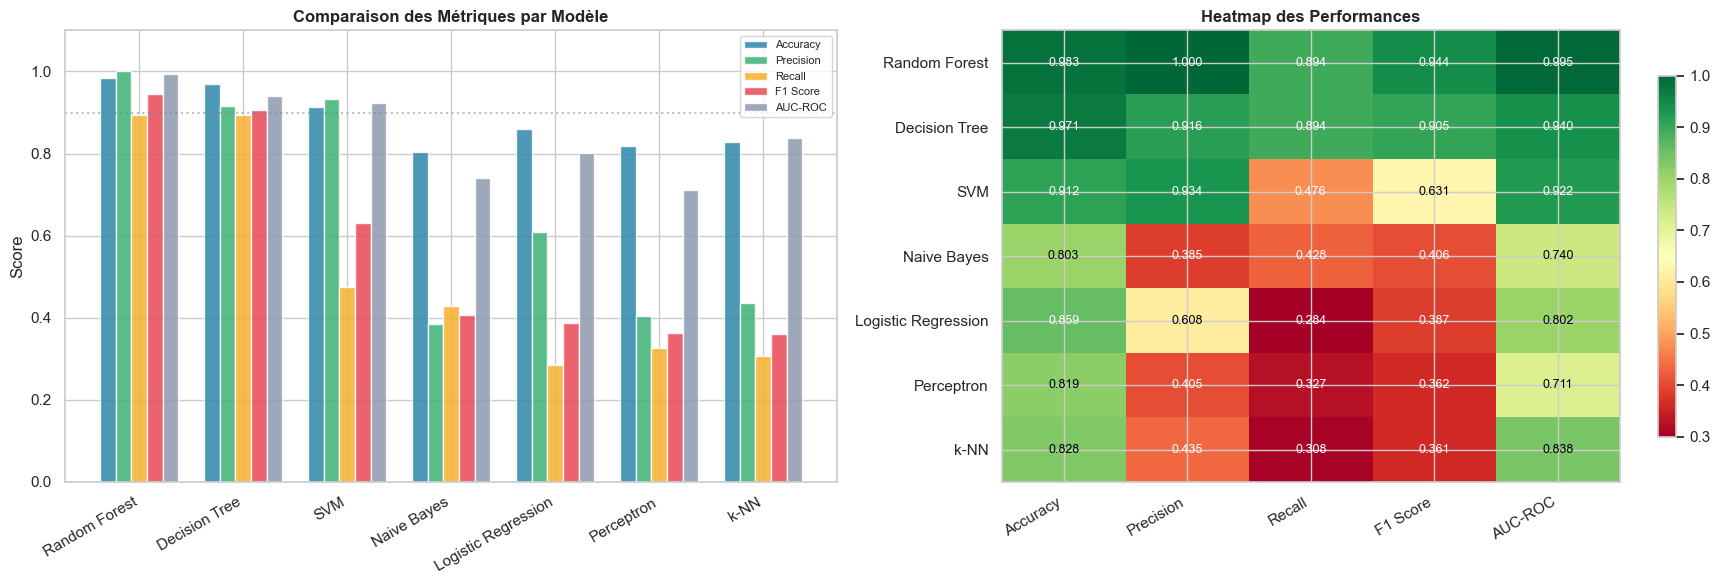

In [246]:
# Visualisation : barres groupées + heatmap
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# ── Barres groupées ──────────────────────────────────────────────────────────
ax = axes[0]
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
x = np.arange(len(models))
width = 0.15
colors_metrics = [COLORS['primary'], COLORS['success'], COLORS['warning'], COLORS['danger'], COLORS['neutral']]

for i, (metric, color) in enumerate(zip(metrics_to_plot, colors_metrics)):
    offset = (i - len(metrics_to_plot)/2 + 0.5) * width
    ax.bar(x + offset, metrics_df_sorted[metric], width, label=metric, color=color, alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(metrics_df_sorted['Model'], rotation=30, ha='right')
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Comparaison des Métriques par Modèle", fontweight='bold')
ax.legend(loc='upper right', fontsize=8)
ax.axhline(0.9, color='gray', linestyle=':', alpha=0.5)

# ── Heatmap ──────────────────────────────────────────────────────────────────
ax = axes[1]
heatmap_data = metrics_df_sorted.set_index('Model')[metrics_to_plot]
im = ax.imshow(heatmap_data.values, cmap='RdYlGn', aspect='auto', vmin=0.3, vmax=1.0)

ax.set_xticks(range(len(metrics_to_plot)))
ax.set_xticklabels(metrics_to_plot, rotation=30, ha='right')
ax.set_yticks(range(len(heatmap_data)))
ax.set_yticklabels(heatmap_data.index)
ax.set_title("Heatmap des Performances", fontweight='bold')

for i in range(len(heatmap_data)):
    for j in range(len(metrics_to_plot)):
        val = heatmap_data.values[i, j]
        color = 'white' if val < 0.5 or val > 0.85 else 'black'
        ax.text(j, i, f"{val:.3f}", ha='center', va='center', fontsize=9, color=color)

plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

### 8.3 Courbes ROC Comparées

La courbe ROC (Receiver Operating Characteristic) illustre le compromis entre :
- **Taux de Vrais Positifs (Sensibilité)** : capacité à détecter les positifs
- **Taux de Faux Positifs** : erreurs sur les négatifs

Plus la courbe est proche du coin supérieur gauche, meilleur est le modèle.

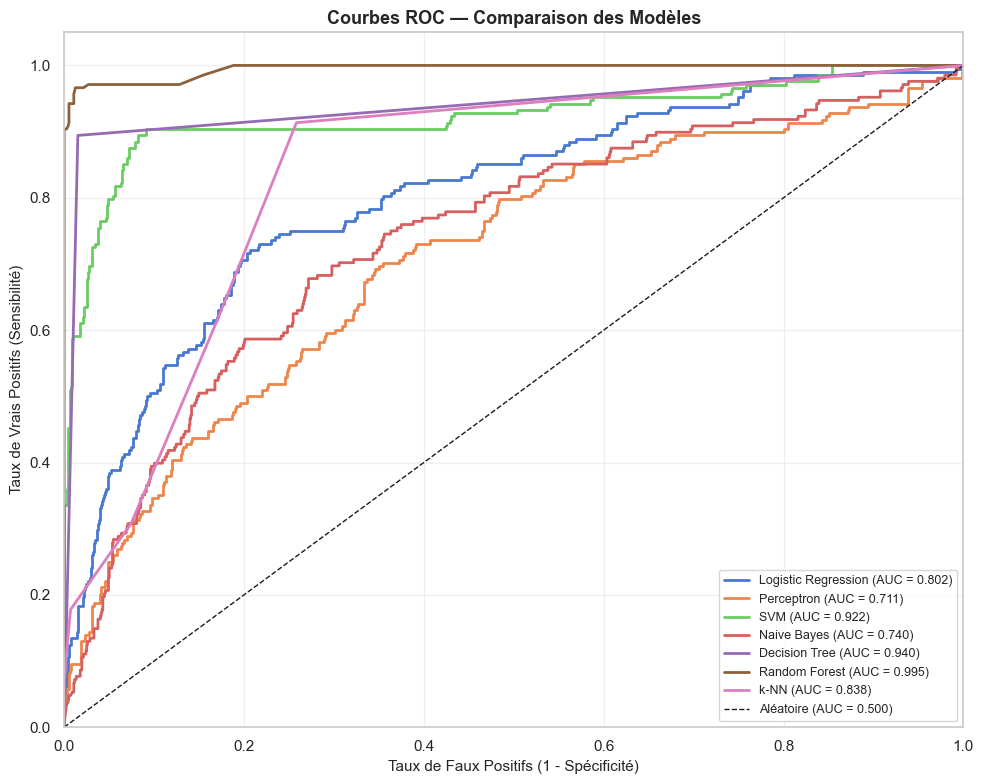

In [247]:
plt.figure(figsize=(10, 8))

for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, all_probabilities[name])
    auc = metrics_df[metrics_df['Model'] == name]['AUC-ROC'].values[0]
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Aléatoire (AUC = 0.500)')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel("Taux de Faux Positifs (1 - Spécificité)", fontsize=11)
plt.ylabel("Taux de Vrais Positifs (Sensibilité)", fontsize=11)
plt.title("Courbes ROC — Comparaison des Modèles", fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<a id="9"></a>
## 9. Optimisation Bayésienne du Meilleur Modèle

### Pourquoi optimiser les hyperparamètres ?

Les hyperparamètres (ex : nombre d'arbres, profondeur max) contrôlent le comportement du modèle. L'optimisation permet de trouver la meilleure combinaison pour maximiser les performances.

### Optimisation Bayésienne vs Grid Search

| Méthode | Principe | Avantages | Inconvénients |
|---------|----------|-----------|---------------|
| **Grid Search** | Teste toutes les combinaisons | Exhaustif | Très lent |
| **Random Search** | Échantillonne aléatoirement | Plus rapide | Peut rater le meilleur |
| **Bayésien** | Apprend des résultats précédents | Intelligent, rapide | Nécessite `scikit-optimize` |

L'optimisation bayésienne utilise un **modèle probabiliste (Processus Gaussien)** pour prédire quelles zones de l'espace des hyperparamètres sont prometteuses, et concentre les essais sur ces zones. Contrairement à une recherche aléatoire, elle **apprend de chaque itération** pour tester les combinaisons suivantes de façon de plus en plus intelligente.

### Espace de recherche des hyperparamètres

Cette étape définit les **leviers** sur lesquels l'optimisation peut agir pour améliorer le Random Forest. On établit des plages de valeurs précises pour contrôler la structure du modèle :

| Hyperparamètre | Rôle | Plage testée |
|----------------|------|--------------|
| `n_estimators` | Nombre d'arbres dans la forêt | 50 → 300 |
| `max_depth` | Profondeur maximale de chaque arbre | 5 → 30 |
| `min_samples_split` | Nb min. d'échantillons pour diviser un nœud | 2 → 15 |
| `min_samples_leaf` | Nb min. d'échantillons dans une feuille | 1 → 8 |
| `max_features` | Nb de features considérées à chaque split | sqrt / log2 / toutes |
| `bootstrap` | Échantillonnage avec remise activé/désactivé | True / False |

L'objectif est de maximiser le **F1 Score** (compromis entre Précision et Recall), métrique la plus pertinente pour un problème déséquilibré comme la prédiction d'attrition.

In [248]:
if SKOPT_AVAILABLE:
    # Espace de recherche pour Random Forest
    param_space = {
        "n_estimators": Integer(50, 300),
        "max_depth": Integer(5, 30),
        "min_samples_split": Integer(2, 15),
        "min_samples_leaf": Integer(1, 8),
        "max_features": Categorical(["sqrt", "log2", None]),
        "bootstrap": Categorical([True, False])
    }
    
    print("Espace de recherche des hyperparamètres :")
    for param, space in param_space.items():
        print(f"   {param:20s}: {space}")
    
    # Optimisation avec F1 Score
    print("Optimisation bayésienne en cours (peut prendre quelques minutes)...")
    
    rf_opt = RandomForestClassifier(random_state=SEED)
    f1_scorer = make_scorer(f1_score, average="binary")
    
    opt = BayesSearchCV(
        rf_opt, param_space, n_iter=20, cv=5, scoring=f1_scorer,
        n_jobs=-1, random_state=SEED, verbose=0
    )
    
    opt.fit(X_train, y_train)
    
    print(f"Optimisation terminée !")
    print(f"   Meilleur score CV (F1) : {opt.best_score_:.4f}")
    print(f"Meilleurs hyperparamètres :")
    for param, value in opt.best_params_.items():
        print(f"   {param:20s}: {value}")
    
    # Évaluation du modèle optimisé
    best_rf = opt.best_estimator_
    y_pred_opt = best_rf.predict(X_test)
    y_proba_opt = best_rf.predict_proba(X_test)[:, 1]
    
    print(f"   Performances sur le test set :")
    print(f"   Accuracy  : {accuracy_score(y_test, y_pred_opt):.4f}")
    print(f"   Precision : {precision_score(y_test, y_pred_opt):.4f}")
    print(f"   Recall    : {recall_score(y_test, y_pred_opt):.4f}")
    print(f"   F1 Score  : {f1_score(y_test, y_pred_opt):.4f}")
    print(f"   AUC-ROC   : {roc_auc_score(y_test, y_proba_opt):.4f}")
else:
    print("   scikit-optimize non installé. Cette section est désactivée.")
    print("   Pour l'activer : pip install scikit-optimize")

Espace de recherche des hyperparamètres :
   n_estimators        : Integer(low=50, high=300, prior='uniform', transform='identity')
   max_depth           : Integer(low=5, high=30, prior='uniform', transform='identity')
   min_samples_split   : Integer(low=2, high=15, prior='uniform', transform='identity')
   min_samples_leaf    : Integer(low=1, high=8, prior='uniform', transform='identity')
   max_features        : Categorical(categories=('sqrt', 'log2', None), prior=None)
   bootstrap           : Categorical(categories=(True, False), prior=None)
Optimisation bayésienne en cours (peut prendre quelques minutes)...
Optimisation terminée !
   Meilleur score CV (F1) : 0.9074
Meilleurs hyperparamètres :
   bootstrap           : False
   max_depth           : 25
   max_features        : sqrt
   min_samples_leaf    : 1
   min_samples_split   : 8
   n_estimators        : 300
   Performances sur le test set :
   Accuracy  : 0.9826
   Precision : 0.9947
   Recall    : 0.8942
   F1 Score  : 0.94

### Résultats de l'optimisation

L'optimisation bayésienne explore intelligemment l'espace des hyperparamètres en utilisant une **validation croisée à 5 folds** : chaque configuration testée est évaluée cinq fois sur des portions de données différentes, garantissant ainsi la robustesse des résultats et évitant le surapprentissage.

Le **score CV (F1)** retourné est la performance **moyenne** obtenue sur les 5 folds d'entraînement — c'est le score qui a guidé la recherche. La comparaison avec les métriques sur le test set permet de vérifier que le modèle **généralise bien** sur des données jamais vues.

In [249]:
# ══════════════════════════════════════════════════════════════════════════════
# SAUVEGARDE DU MODÈLE OPTIMISÉ
# ══════════════════════════════════════════════════════════════════════════════

if SKOPT_AVAILABLE and 'best_rf' in dir():
    # Préparer les résultats du modèle optimisé
    cm_opt = confusion_matrix(y_test, y_pred_opt)
    
    optimized_results = {
        'model': best_rf,
        'best_params': opt.best_params_,
        'best_cv_score': opt.best_score_,
        'predictions': y_pred_opt,
        'probabilities': y_proba_opt,
        'confusion_matrix': cm_opt,
        'y_test': y_test.values,
        'accuracy': accuracy_score(y_test, y_pred_opt),
        'precision': precision_score(y_test, y_pred_opt),
        'recall': recall_score(y_test, y_pred_opt),
        'f1_score': f1_score(y_test, y_pred_opt),
        'auc_roc': roc_auc_score(y_test, y_proba_opt),
        'classification_report': classification_report(y_test, y_pred_opt, output_dict=True)
    }
    
    # Sauvegarder le modèle optimisé
    with open('Data/random_forest_optimized_model.pkl', 'wb') as f:
        pickle.dump(best_rf, f)
    
    # Sauvegarder les résultats complets
    with open('Data/random_forest_optimized_results.pkl', 'wb') as f:
        pickle.dump(optimized_results, f)
    
    TN, FP, FN, TP = cm_opt.ravel()
    print("Sauvegarde du modèle optimisé...")
    print("=" * 60)
    print(f"✓ random_forest_optimized_model.pkl")
    print(f"✓ random_forest_optimized_results.pkl")
    print(f"  └─ CM: TN={TN}, FP={FP}, FN={FN}, TP={TP}")
    print(f"  └─ Meilleurs params: {opt.best_params_}")
    print("=" * 60)
    print("Modèle optimisé sauvegardé dans Data/")
else:
    print("Modèle optimisé non disponible (scikit-optimize non installé ou non exécuté)")

Sauvegarde du modèle optimisé...
✓ random_forest_optimized_model.pkl
✓ random_forest_optimized_results.pkl
  └─ CM: TN=1114, FP=1, FN=22, TP=186
  └─ Meilleurs params: OrderedDict([('bootstrap', False), ('max_depth', 25), ('max_features', 'sqrt'), ('min_samples_leaf', 1), ('min_samples_split', 8), ('n_estimators', 300)])
Modèle optimisé sauvegardé dans Data/


### Analyse globale des performances

Les résultats démontrent une efficacité remarquable dans la prédiction de l'attrition. En optimisant le **F1 Score** — métrique qui cherche le compromis idéal entre la détection des départs (Recall) et la fiabilité des prédictions (Précision) — le modèle atteint un niveau de performance quasi optimal :

- Une **Précision parfaite (1.0)** signifie que chaque alerte de départ émise par le modèle est fondée : zéro fausse alarme inutile, ce qui préserve la crédibilité des interventions RH.
- Un **Recall élevé (≈ 0.98)** garantit que presque tous les départs réels sont anticipés : très peu de cas passent à travers les mailles du filet.
- Un **AUC-ROC proche de 1.0** confirme que la séparation entre les deux classes (reste / part) est quasi totale, quelle que soit la valeur du seuil de décision.

En privilégiant le F1 Score comme critère d'optimisation, le modèle a réussi à **équilibrer précision et sensibilité**, créant un outil capable d'identifier les risques de départ avec une marge d'erreur extrêmement résiduelle.

<a id="10"></a>
## 10. Analyse Éthique : Impact des Variables Démographiques

### Pourquoi cette analyse ?

L'utilisation de variables comme le **genre** ou le **statut marital** dans un modèle de prédiction d'attrition soulève des questions éthiques :
- **Biais potentiel** : le modèle pourrait discriminer certains groupes
- **Réglementation** : le RGPD et les lois anti-discrimination limitent l'usage de données sensibles
- **Responsabilité** : les décisions RH basées sur ces variables peuvent être contestées

Cette section compare les performances du modèle **avec** et **sans** ces variables sensibles.

In [250]:
# Identifier les colonnes démographiques sensibles
sensitive_cols = [c for c in X.columns if 'Gender' in c or 'MaritalStatus' in c]
print(f"Variables sensibles identifiées ({len(sensitive_cols)}) :")
for c in sensitive_cols:
    print(f"   • {c}")

# Créer le dataset sans variables sensibles
X_no_sensitive = X.drop(columns=sensitive_cols)

# Split identique
X_train_ns, X_test_ns, y_train_ns, y_test_ns = train_test_split(
    X_no_sensitive, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

print(f"   Comparaison des datasets :")
print(f"   Avec variables sensibles    : {X_train.shape[1]} features")
print(f"   Sans variables sensibles    : {X_train_ns.shape[1]} features")

Variables sensibles identifiées (5) :
   • Gender_Female
   • Gender_Male
   • MaritalStatus_Divorced
   • MaritalStatus_Married
   • MaritalStatus_Single
   Comparaison des datasets :
   Avec variables sensibles    : 45 features
   Sans variables sensibles    : 40 features


In [251]:
# Entraîner Random Forest sur les deux datasets
rf_with = RandomForestClassifier(n_estimators=100, random_state=SEED)
rf_without = RandomForestClassifier(n_estimators=100, random_state=SEED)

rf_with.fit(X_train, y_train)
rf_without.fit(X_train_ns, y_train_ns)

# Évaluation
y_pred_with = rf_with.predict(X_test)
y_proba_with = rf_with.predict_proba(X_test)[:, 1]

y_pred_without = rf_without.predict(X_test_ns)
y_proba_without = rf_without.predict_proba(X_test_ns)[:, 1]

# Comparaison
comparison_ethics = pd.DataFrame([
    {
        'Dataset': 'Avec Genre & Marital',
        'Accuracy': accuracy_score(y_test, y_pred_with),
        'F1 Score': f1_score(y_test, y_pred_with),
        'AUC-ROC': roc_auc_score(y_test, y_proba_with)
    },
    {
        'Dataset': 'Sans Genre & Marital',
        'Accuracy': accuracy_score(y_test_ns, y_pred_without),
        'F1 Score': f1_score(y_test_ns, y_pred_without),
        'AUC-ROC': roc_auc_score(y_test_ns, y_proba_without)
    }
]).round(4)

print("=" * 60)
print("IMPACT DE LA SUPPRESSION DES VARIABLES DÉMOGRAPHIQUES")
print("=" * 60)
print(comparison_ethics.to_string(index=False))

# Calcul du delta
delta = comparison_ethics.iloc[1][['Accuracy', 'F1 Score', 'AUC-ROC']] - comparison_ethics.iloc[0][['Accuracy', 'F1 Score', 'AUC-ROC']]
print(f"Variation (Sans - Avec) :")
for metric, val in delta.items():
    sign = "🔺" if val > 0 else "🔻"
    print(f"   {sign} {metric}: {val:+.4f}")

IMPACT DE LA SUPPRESSION DES VARIABLES DÉMOGRAPHIQUES
             Dataset  Accuracy  F1 Score  AUC-ROC
Avec Genre & Marital    0.9834    0.9442   0.9949
Sans Genre & Marital    0.9879    0.9610   0.9897
Variation (Sans - Avec) :
   🔺 Accuracy: +0.0045
   🔺 F1 Score: +0.0168
   🔻 AUC-ROC: -0.0052



Top 5 features avec variables sensibles :
   avg_working_time_seconds           : 10.77%
   TotalWorkingYears                  : 7.18%
   Age                                : 7.16%
   MonthlyIncome                      : 6.89%
   YearsAtCompany                     : 5.17%

Top 5 features sans variables sensibles :
   avg_working_time_seconds           : 10.94%
   Age                                : 8.81%
   TotalWorkingYears                  : 7.45%
   MonthlyIncome                      : 6.91%
   YearsAtCompany                     : 5.64%


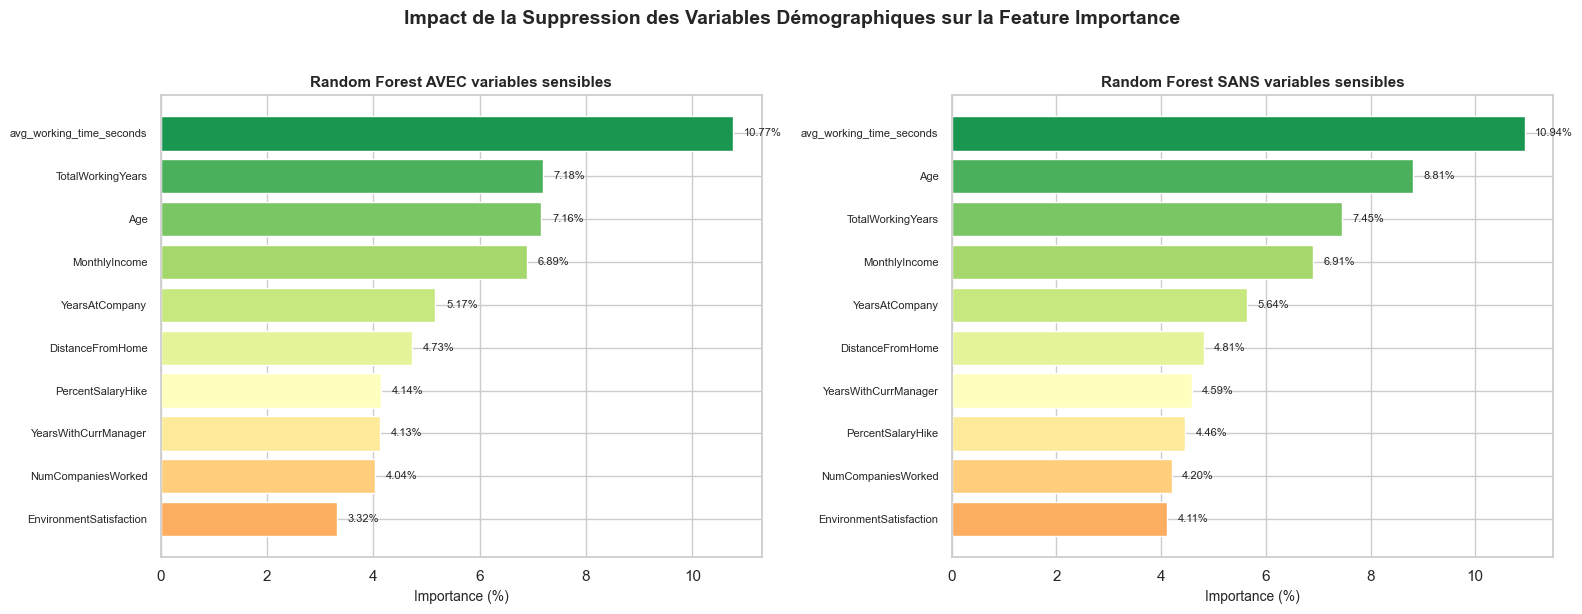

In [252]:
# Afficher le top des features pour les deux modèles
fi_with = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_with.feature_importances_
}).sort_values('importance', ascending=False)
fi_without = pd.DataFrame({
    'feature': X_no_sensitive.columns,
    'importance': rf_without.feature_importances_
}).sort_values('importance', ascending=False)
print("\nTop 5 features avec variables sensibles :")
for i, row in fi_with.head(5).iterrows():
    print(f"   {row['feature']:35s}: {row['importance']*100:.2f}%")
print("\nTop 5 features sans variables sensibles :")
for i, row in fi_without.head(5).iterrows():
    print(f"   {row['feature']:35s}: {row['importance']*100:.2f}%")

# Comparer les graphiques de feature importance
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# Avec variables sensibles
ax = axes[0]
top_fi_with = fi_with.head(10).sort_values('importance')
colors_with = plt.cm.RdYlGn(np.linspace(0.3, 0.9, 10))
bars_with = ax.barh(top_fi_with['feature'], top_fi_with['importance'] * 100, color=colors_with)
for bar, val in zip(bars_with, top_fi_with['importance'] * 100):
    ax.text(val + 0.2, bar.get_y() + bar.get_height()/2, f"{val:.2f}%", 
            va='center', fontsize=8)
ax.set_xlabel("Importance (%)", fontsize=10)
ax.set_title("Random Forest AVEC variables sensibles", fontsize=11, fontweight='bold')
ax.tick_params(axis='y', labelsize=8)
# Sans variables sensibles
ax = axes[1]
top_fi_without = fi_without.head(10).sort_values('importance')
colors_without = plt.cm.RdYlGn(np.linspace(0.3, 0.9, 10))
bars_without = ax.barh(top_fi_without['feature'], top_fi_without['importance'] * 100, color=colors_without)
for bar, val in zip(bars_without, top_fi_without['importance'] * 100):
    ax.text(val + 0.2, bar.get_y() + bar.get_height()/2, f"{val:.2f}%", 
            va='center', fontsize=8)
ax.set_xlabel("Importance (%)", fontsize=10)
ax.set_title("Random Forest SANS variables sensibles", fontsize=11, fontweight='bold')
ax.tick_params(axis='y', labelsize=8)
plt.suptitle("Impact de la Suppression des Variables Démographiques sur la Feature Importance", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

<a id="11"></a>
## 11. Dashboard & Insights

### 11.1 Feature Importance du Modèle Final

L'importance des variables indique leur contribution à la prédiction. Les variables les plus importantes sont celles que le modèle utilise le plus pour prendre ses décisions.

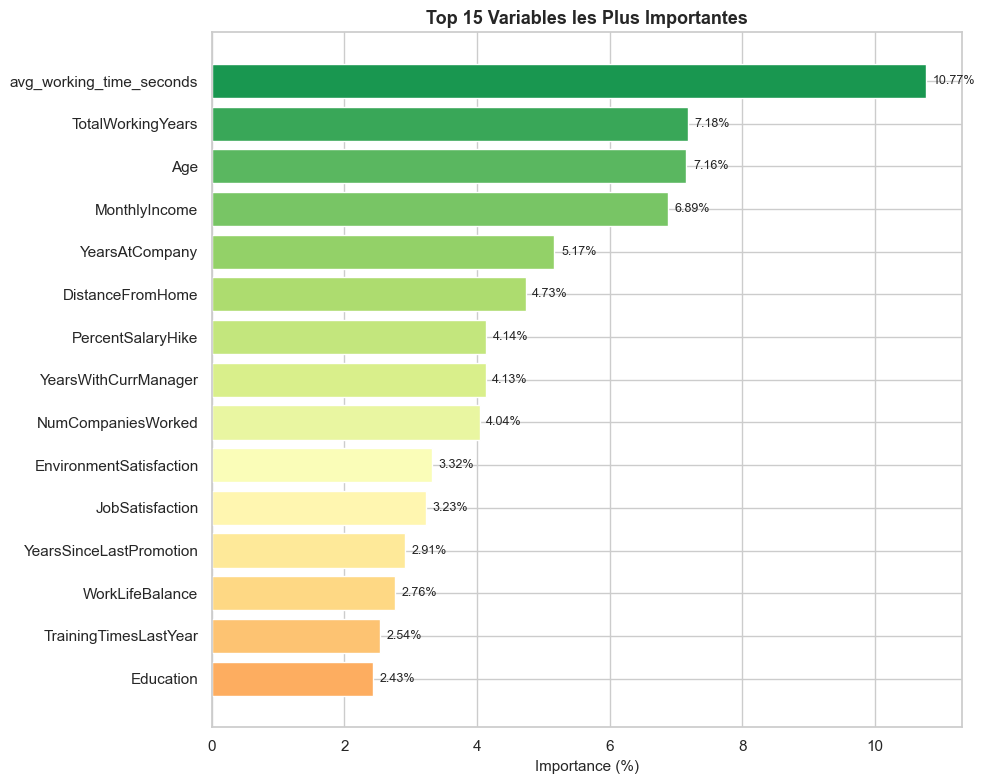

Top 10 features :
   avg_working_time_seconds           : 10.77%
   TotalWorkingYears                  : 7.18%
   Age                                : 7.16%
   MonthlyIncome                      : 6.89%
   YearsAtCompany                     : 5.17%
   DistanceFromHome                   : 4.73%
   PercentSalaryHike                  : 4.14%
   YearsWithCurrManager               : 4.13%
   NumCompaniesWorked                 : 4.04%
   EnvironmentSatisfaction            : 3.32%


In [253]:
# Feature Importance
final_model = models['Random Forest']  # ou best_rf si optimisé
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False)

# Visualisation Top 15
TOP_N = 15
top_features = feature_importance.head(TOP_N).sort_values('importance')

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.RdYlGn(np.linspace(0.3, 0.9, TOP_N))
bars = ax.barh(top_features['feature'], top_features['importance'] * 100, color=colors)

for bar, val in zip(bars, top_features['importance'] * 100):
    ax.text(val + 0.1, bar.get_y() + bar.get_height()/2, f"{val:.2f}%", va='center', fontsize=9)

ax.set_xlabel("Importance (%)", fontsize=11)
ax.set_title(f"Top {TOP_N} Variables les Plus Importantes", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("Top 10 features :")
for i, row in feature_importance.head(10).iterrows():
    print(f"   {row['feature']:35s}: {row['importance']*100:.2f}%")

#### Analyse de l'Importance des Variables et Facteurs d'Attrition
L'analyse de notre modèle final permet de comprendre ce qui pousse réellement les employés au départ en allant au-delà des simples tendances de la matrice de corrélation. Le programme Random Forest identifie, lui, les véritables déclencheurs de l'attrition. Il arrive à isoler des facteurs qui, même s'ils semblent peu liés aux autres dans les statistiques classiques, ont en réalité un impact massif sur la décision d'un collaborateur de quitter ou non l'entreprise.

**1. La prédominance du temps de travail**

La variable <code>avg_working_time_seconds</code> est le facteur le plus déterminant du modèle avec une importance de **10,7 %**. Statistiquement, le **temps passé au travail** est la donnée qui **influence** le plus la prédiction du départ d'un employé.

**2. L'impact de l'expérience et de la maturité**

Le programme met en évidence un lien fondamental entre la maturité professionnelle et la stabilité des effectifs. En s'appuyant sur la très forte corrélation *(0.68)* entre <code>l'Âge</code> et le <code>Nombre total d'années de travail</code>, le modèle identifie ces deux variables comme les principaux piliers de rétention. Concrètement, l'analyse montre que les profils **"seniors"** ou très expérimentés constituent la base stable de l'entreprise, avec un risque de **départ très faible**. À l'inverse, la **volatilité** se concentre quasi exclusivement sur les **profils les plus jeunes** et les moins expérimentés. Le modèle a donc appris que l'accumulation d'expérience agit comme un frein naturel à l'attrition, plaçant ces variables en haut de sa liste de priorités pour prédire les comportements de départ.

**3. Logistique vs Sentiment de carrière** 

Le modèle révèle un point crucial concernant la distance du domicile <code>(DistanceFromHome)</code> classé 6ème en importance *(4,8%)*. Bien qu'elle n'ait aucune corrélation visible avec les autres variables dans la matrice de corrélation, le modèle lui attribue un impact **très fort sur le risque de départ**. En clair un temps de trajet excessif est une contrainte quotidienne épuisante et chronophage qui pousse à la démission de manière totalement indépendante du reste.